# What Determines a Car's Fuel Economy?
### Auto MPG (1970–1982): exploratory analysis, fifteen-model benchmark, and the lessons the data teaches

---

The Auto MPG dataset records the fuel economy of 398 cars sold in the United States between 1970 and 1982, together with engine size, power, weight, acceleration, model year, region of origin and the car's name. The study sets out to answer two kinds of question.

**About the cars**
1. Which physical characteristics determine fuel economy, and in what functional form?
2. How much did fuel economy improve over the decade, and how much of that came from lighter cars rather than better technology?
3. Are Japanese and European cars really more efficient, or just smaller?
4. What does the data leave out? For example, diesel engines are not a column, but they appear in the car names.

**About modelling**
1. Can a simple model built on a physical relationship match flexible machine-learning models on 400 rows?
2. How much of a reported test error is luck of the split?
3. Which conclusions about "important features" hold up, and which are artefacts of correlated inputs?

Each section ends with a **"What we learn"** box whose numbers are computed from the results of that run. The final chapter gathers all of them into one summary.

| § | Content |
|---|---|
| 1 | Setup |
| 2 | Data acquisition, cleaning and information recovered from car names |
| 3 | Exploratory analysis: physics, collinearity, the technology trend, origin, diesels |
| 4 | Validation design and baseline |
| 5 | Benchmark of 15 models on two feature sets |
| 6 | Hyperparameter tuning |
| 7 | Hold-out evaluation and error analysis |
| 8 | Robustness: split variance and repeated car models |
| 9 | Interpretation: grouped importance, coefficient stability, effect sizes |
| 10 | Data requirements |
| 11 | Prediction tool and export |
| 12 | **Key learnings** |

## 1 · Setup

In [1]:
%pip install -q xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.


In [2]:
import io
import re
import sys
import json
import time
import shutil
import platform
import warnings
from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from scipy.stats import loguniform, randint, uniform
from IPython.display import display, Markdown

import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, SplineTransformer, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold, GroupKFold, cross_validate,
                                     cross_val_predict, RandomizedSearchCV)
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from sklearn.neural_network import MLPRegressor

import xgboost
import lightgbm
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
VERSIONS = {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__,
            "lightgbm": lightgbm.__version__, "pandas": pd.__version__}
print(" | ".join(f"{k} {v}" for k, v in VERSIONS.items()))

python 3.11.9 | scikit-learn 1.9.1 | xgboost 3.2.0 | lightgbm 4.7.0 | pandas 3.0.6


In [3]:
CONFIG = {
    "seed": 42,
    "test_size": 0.20,
    "cv_splits": 5,
    "cv_repeats": 5,
    "search_iter": 25,
    "robustness_splits": 30,
    "bootstrap": 1000,
    "conformal_alpha": 0.10,
    "quick_run": False,
    "uci_url": "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data",
}
if CONFIG["quick_run"]:
    CONFIG.update(cv_repeats=1, search_iter=4, robustness_splits=5, bootstrap=200)

HOME = (Path("/content") if IN_COLAB else Path.cwd()) / "auto_mpg_study"
DIRS = {k: HOME / k for k in ("figures", "tables", "model")}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
SEED = CONFIG["seed"]

**Style, helpers and the learning log.** `learn()` shows a "What we learn" box and also records it, so that §12 can gather every finding in one place.

In [4]:
INK, TEAL, ORANGE, PLUM, SAND, GREY = "#22223B", "#0F766E", "#EA580C", "#6D28D9", "#D6CCC2", "#9CA3AF"
REGION_COLORS = {"USA": "#1D4ED8", "Europe": "#059669", "Japan": "#DC2626"}

sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11.5, "axes.titlelocation": "left", "axes.labelcolor": INK,
    "axes.edgecolor": "#4B5563", "xtick.color": INK, "ytick.color": INK, "legend.frameon": False,
    "axes.prop_cycle": plt.cycler(color=[TEAL, ORANGE, PLUM, "#B45309", "#0369A1", GREY]),
})

LEARNINGS = defaultdict(list)


def learn(category, text):
    LEARNINGS[category].append(text)
    display(Markdown(f"> **What we learn · {category}.** {text}"))


def savefig(fig, name):
    fig.savefig(DIRS["figures"] / f"{name}.png", bbox_inches="tight", facecolor="white")


def savetab(frame, name):
    frame.to_csv(DIRS["tables"] / f"{name}.csv")


def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))


def ols(X, y):
    X1 = np.column_stack([np.ones(len(X)), np.asarray(X, float)])
    beta, *_ = np.linalg.lstsq(X1, y, rcond=None)
    resid = y - X1 @ beta
    dof = len(y) - X1.shape[1]
    cov = (resid @ resid / dof) * np.linalg.pinv(X1.T @ X1)
    return beta, np.sqrt(np.diag(cov)), 1 - resid.var() / np.var(y), resid

## 2 · Data

### 2.1 Acquisition
Sources are tried in this order:
1. a local copy of the data file;
2. the `mpg` dataset in the seaborn data repository;
3. the UCI repository;
4. a file-upload prompt.

All sources share the same schema once loaded.

In [5]:
UCI_COLUMNS = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "year", "origin", "name"]


def read_uci(source):
    return pd.read_csv(source, sep=r"\s+", names=UCI_COLUMNS, na_values="?", quotechar='"')


def acquire():
    for p in [Path("auto-mpg.data"), Path("data/raw/auto-mpg.data"), Path("../data/raw/auto-mpg.data"),
              Path("/content/auto-mpg.data")]:
        if p.exists():
            return read_uci(p), f"local file {p}"
    for p in [Path("auto-mpg.csv"), Path("mpg.csv"), Path("/content/auto-mpg.csv")]:
        if p.exists():
            return pd.read_csv(p, na_values="?"), f"local file {p}"
    try:
        return sns.load_dataset("mpg"), "seaborn-data repository"
    except Exception as exc:
        print(f"seaborn source unavailable: {exc}")
    try:
        return read_uci(CONFIG["uci_url"]), "UCI repository"
    except Exception as exc:
        print(f"UCI source unavailable: {exc}")
    if IN_COLAB:
        from google.colab import files
        up = files.upload()
        key = next(iter(up))
        return (read_uci(io.BytesIO(up[key])) if key.endswith(".data") else pd.read_csv(io.BytesIO(up[key]), na_values="?")), f"upload {key}"
    raise FileNotFoundError("Auto MPG data not found")


raw, source = acquire()
print(f"Loaded {raw.shape[0]} rows from {source}")
display(raw.head())

Loaded 398 rows from seaborn-data repository


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


### 2.2 Cleaning and harmonisation
The cleaning steps are:
- column names are unified (seaborn uses `model_year` where the UCI file uses `year`);
- the region of origin is decoded;
- `horsepower` is converted to a number, keeping missing values as missing;
- brand names are extracted from the car names and misspellings corrected;
- fuel consumption is added as gallons per 100 miles, $GPM = 100/MPG$, and in L/100 km.

Missing horsepower values are **not** filled in here. They are imputed inside each model pipeline, so the imputation only ever sees training data.

In [6]:
BRAND_FIX = {"chevroelt": "chevrolet", "chevy": "chevrolet", "maxda": "mazda", "toyouta": "toyota",
             "vokswagen": "volkswagen", "vw": "volkswagen", "mercedes-benz": "mercedes", "mercedes benz": "mercedes",
             "capri": "ford", "hi": "international"}
REGION_MAP = {1: "USA", 2: "Europe", 3: "Japan", "usa": "USA", "europe": "Europe", "japan": "Japan"}

cars = raw.rename(columns={"model_year": "year"}).copy()
cars["horsepower"] = pd.to_numeric(cars["horsepower"], errors="coerce")
cars["region"] = cars["origin"].map(lambda v: REGION_MAP.get(v, REGION_MAP.get(str(v).lower(), str(v))))
cars["name"] = cars["name"].astype(str).str.strip().str.lower()
cars["brand"] = cars["name"].str.split().str[0].replace(BRAND_FIX)
cars["model_name"] = cars["name"].str.replace(r"\s+", " ", regex=True)
cars["year"] = cars["year"].astype(int)
cars["year"] = np.where(cars["year"] < 100, cars["year"] + 1900, cars["year"])
cars["gpm"] = 100 / cars["mpg"]
cars["l_per_100km"] = 235.215 / cars["mpg"]
cars["weight_kg"] = cars["weight"] * 0.45359
cars = cars.drop(columns=["origin"])

audit = pd.Series({
    "cars": len(cars),
    "missing horsepower": int(cars["horsepower"].isna().sum()),
    "exact duplicate rows": int(cars.duplicated().sum()),
    "distinct car names": cars["name"].nunique(),
    "names appearing in more than one row": int((cars["name"].value_counts() > 1).sum()),
    "brands (after correction)": cars["brand"].nunique(),
    "model years": f"{cars['year'].min()}–{cars['year'].max()}",
}, name="value")
display(audit.to_frame())
display(cars["region"].value_counts().rename("cars").to_frame().T)

,value
cars,398
missing horsepower,6
exact duplicate rows,0
distinct car names,305
names appearing in more than one row,56
brands (after correction),29
model years,1970–1982


region,USA,Japan,Europe
cars,249,79,70


### 2.3 Information hidden in the car names
The car names contain facts that no numeric column records. **Diesel** engines, for example "mercedes-benz 240d" or "oldsmobile cutlass ciera (diesel)", have a different combustion process and much better fuel economy for their size. **Station wagons**, marked "(sw)" or "wagon", are heavier bodies built on the same platforms. Both are extracted as indicator flags.

In [7]:
cars["diesel"] = cars["name"].str.contains(r"diesel|\b\d{3}d\b", regex=True).astype(int)
cars["wagon"] = cars["name"].str.contains(r"\(sw\)|wagon|estate|\bsw\b", regex=True).astype(int)
display(cars.loc[cars["diesel"] == 1, ["name", "year", "weight", "horsepower", "mpg"]].sort_values("mpg", ascending=False))
flags = pd.DataFrame({"cars": [cars["diesel"].sum(), cars["wagon"].sum()],
                      "median mpg (flag)": [cars.loc[cars["diesel"] == 1, "mpg"].median(), cars.loc[cars["wagon"] == 1, "mpg"].median()],
                      "median mpg (others)": [cars.loc[cars["diesel"] == 0, "mpg"].median(), cars.loc[cars["wagon"] == 0, "mpg"].median()]},
                     index=["diesel", "wagon"])
display(flags.style.format(precision=1))
learn("data", f"The dataset has {len(cars)} cars and {int(cars['horsepower'].isna().sum())} missing horsepower values. "
      f"{cars['name'].nunique()} distinct names appear, so some car models are recorded more than once. "
      f"The names reveal {int(cars['diesel'].sum())} diesel cars and {int(cars['wagon'].sum())} station wagons, information that no numeric column contains.")

,name,year,weight,horsepower,mpg
325,vw rabbit c (diesel),1980,2085,48.0,44.3
326,vw dasher (diesel),1980,2335,48.0,43.4
244,volkswagen rabbit custom diesel,1978,1985,48.0,43.1
387,oldsmobile cutlass ciera (diesel),1982,3015,85.0,38.0
327,audi 5000s (diesel),1980,2950,67.0,36.4
360,volvo diesel,1981,3160,76.0,30.7
328,mercedes-benz 240d,1980,3250,67.0,30.0
359,peugeot 505s turbo diesel,1981,3230,80.0,28.1
297,mercedes benz 300d,1979,3530,77.0,25.4


,cars,median mpg (flag),median mpg (others)
diesel,9,36.4,22.3
wagon,29,18.0,23.2


> **What we learn · data.** The dataset has 398 cars and 6 missing horsepower values. 305 distinct names appear, so some car models are recorded more than once. The names reveal 9 diesel cars and 29 station wagons, information that no numeric column contains.

## 3 · Exploratory Analysis

### 3.1 Choosing the right scale for the target
Fuel economy can be expressed as distance per fuel (MPG) or as fuel per distance (GPM, or L/100 km). Physics suggests that fuel **consumption** is the natural quantity, because the energy needed to move a car is roughly proportional to its mass. This section compares the two scales on their distribution and on how linearly each relates to weight.

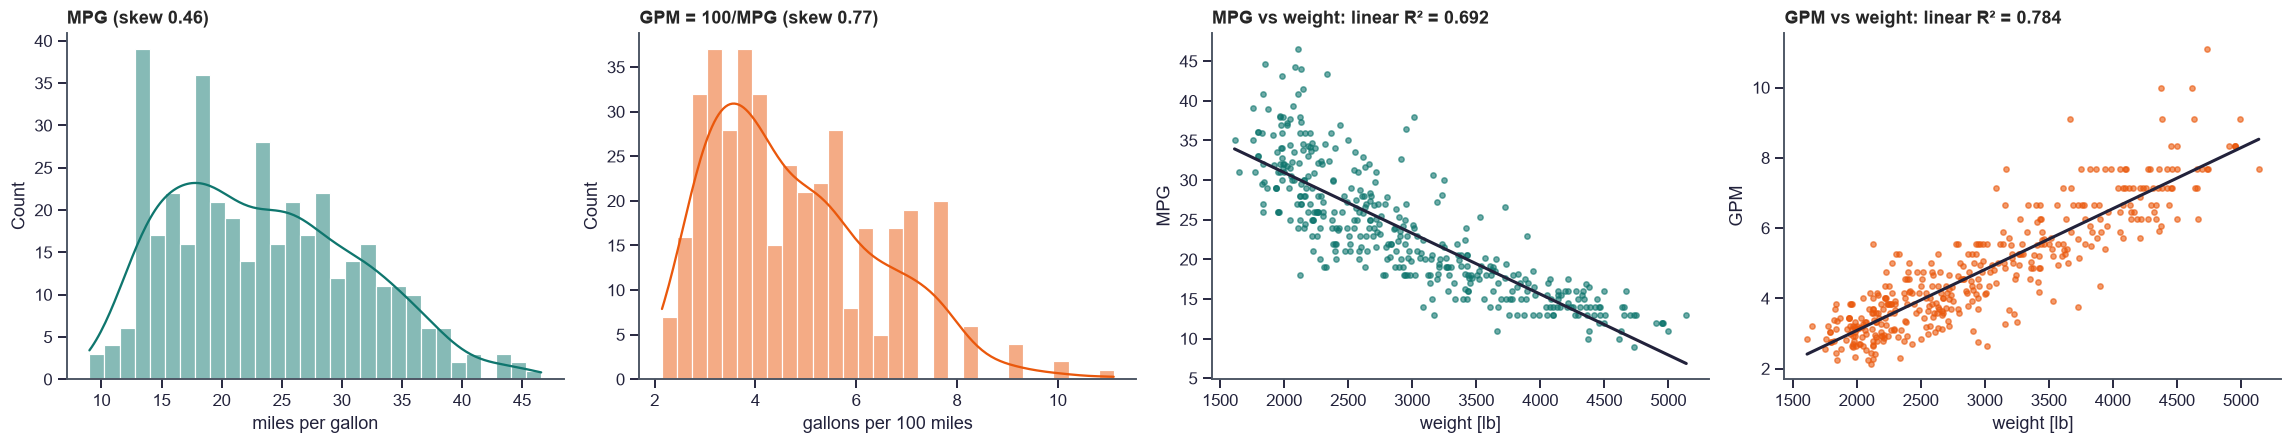

> **What we learn · domain.** Fuel consumption (GPM) depends on weight much more linearly than MPG does: a straight line explains R² = 0.784 of GPM variation, against 0.692 for MPG. The curved relationship noted in the original EDA is mostly a consequence of measuring efficiency as distance per gallon rather than fuel per distance.

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
sns.histplot(cars["mpg"], bins=30, kde=True, ax=axes[0], color=TEAL)
axes[0].set(title=f"MPG (skew {cars['mpg'].skew():.2f})", xlabel="miles per gallon")
sns.histplot(cars["gpm"], bins=30, kde=True, ax=axes[1], color=ORANGE)
axes[1].set(title=f"GPM = 100/MPG (skew {cars['gpm'].skew():.2f})", xlabel="gallons per 100 miles")

fit_rows = {}
for ax, target, color in [(axes[2], "mpg", TEAL), (axes[3], "gpm", ORANGE)]:
    ax.scatter(cars["weight"], cars[target], s=12, alpha=0.6, color=color)
    b, _, r2, _ = ols(cars[["weight"]].to_numpy(), cars[target].to_numpy())
    xs = np.linspace(cars["weight"].min(), cars["weight"].max(), 50)
    ax.plot(xs, b[0] + b[1] * xs, color=INK, lw=2)
    fit_rows[target] = r2
    ax.set(title=f"{target.upper()} vs weight: linear R² = {r2:.3f}", xlabel="weight [lb]", ylabel=target.upper())
fig.tight_layout()
savefig(fig, "3_1_target_scale")
plt.show()

learn("domain", f"Fuel consumption (GPM) depends on weight much more linearly than MPG does: a straight line explains "
      f"R² = {fit_rows['gpm']:.3f} of GPM variation, against {fit_rows['mpg']:.3f} for MPG. The curved relationship noted in "
      f"the original EDA is mostly a consequence of measuring efficiency as distance per gallon rather than fuel per distance.")

### 3.2 Collinearity of the size variables
Cylinders, displacement, horsepower and weight all measure how big a car and its engine are. The variance inflation factor (VIF) measures how well each variable can be predicted from the others. A VIF above 10 means a linear model cannot reliably separate that variable's effect from the others.

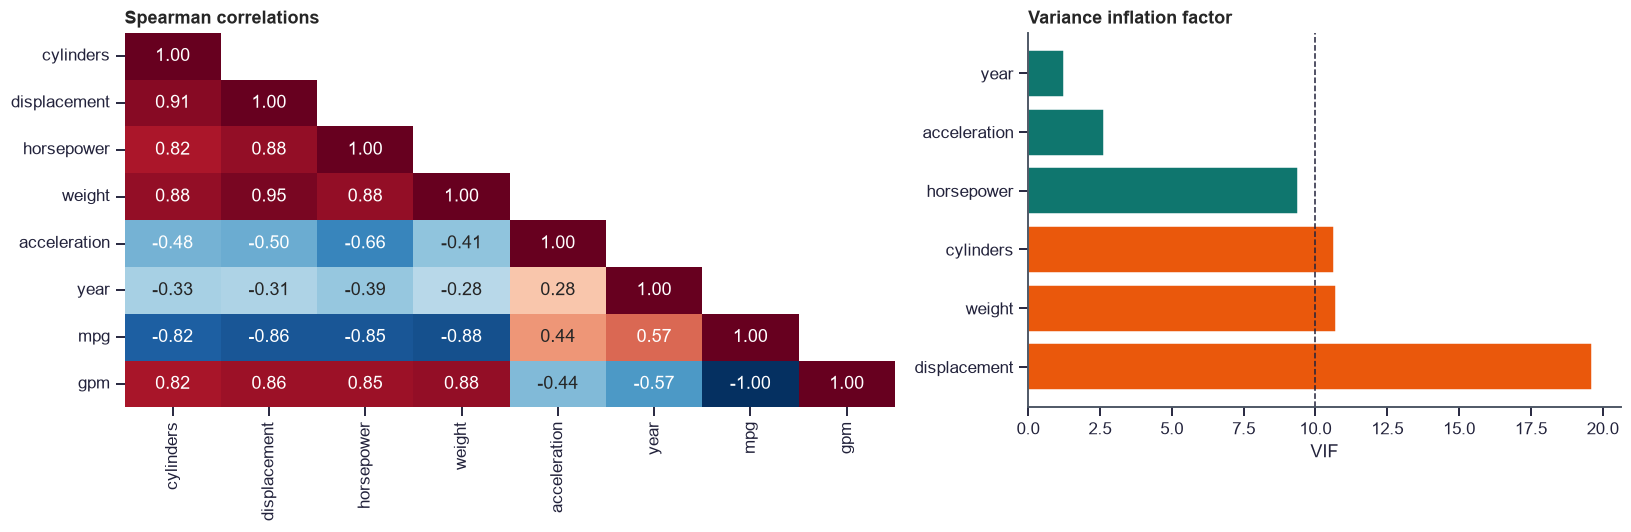

> **What we learn · data.** 3 of the 6 numeric inputs have VIF > 10 (displacement 20, weight 11, cylinders 11). These variables share most of their information, so any single coefficient or importance score for one of them should not be read as that variable's separate effect.

In [9]:
NUMERIC = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "year"]
complete = cars.dropna(subset=NUMERIC)
vif = {}
for c in NUMERIC:
    others = [o for o in NUMERIC if o != c]
    _, _, r2, _ = ols(complete[others].to_numpy(), complete[c].to_numpy())
    vif[c] = 1 / max(1 - r2, 1e-9)
vif = pd.Series(vif, name="VIF").sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.3, 1]})
corr = complete[NUMERIC + ["mpg", "gpm"]].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0], cbar=False,
            mask=np.triu(np.ones_like(corr, dtype=bool), 1))
axes[0].set_title("Spearman correlations")
axes[1].barh(vif.index, vif.values, color=[ORANGE if v > 10 else TEAL for v in vif.values])
axes[1].axvline(10, ls="--", c=INK, lw=1)
axes[1].set(title="Variance inflation factor", xlabel="VIF")
fig.tight_layout()
savefig(fig, "3_2_collinearity")
plt.show()

high = vif[vif > 10]
learn("data", f"{len(high)} of the {len(NUMERIC)} numeric inputs have VIF > 10 ({', '.join(f'{k} {v:.0f}' for k, v in high.items())}). "
      f"These variables share most of their information, so any single coefficient or importance score for one of them "
      f"should not be read as that variable's separate effect.")

### 3.3 The technology trend: lighter cars or better engineering?
Average fuel economy rose sharply over the period, after the 1973 and 1979 oil crises and the introduction of US fuel-economy standards (CAFE) from model year 1978. To separate the reasons, the model

$$\log GPM = \alpha + \beta \log W + \gamma_{\text{year}} + \varepsilon$$

is fitted. The coefficient $\beta$ is the elasticity of fuel use with respect to weight $W$. The year effects $\gamma$ measure efficiency gains **at equal weight**, i.e. technology. The overall change in average $\log GPM$ between the first and last year then splits exactly into a weight component, $\beta\,\Delta\overline{\log W}$, and a technology component, $\Delta\gamma$.

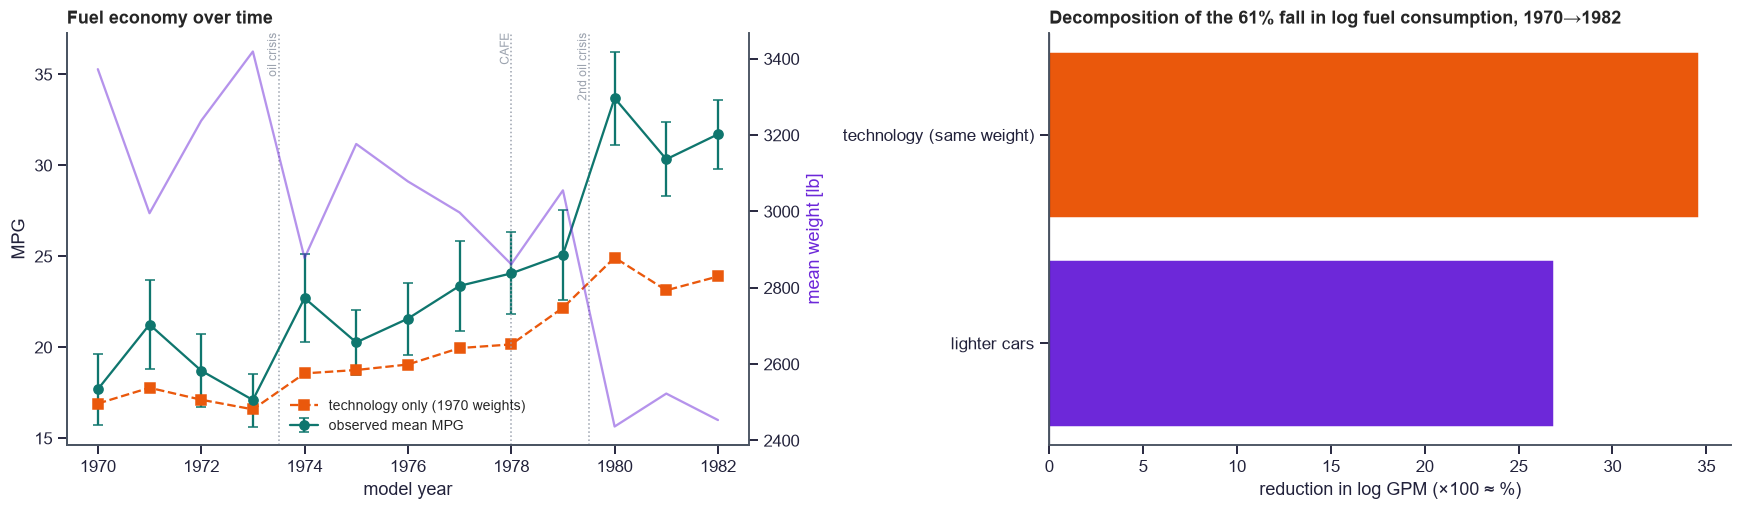

Weight elasticity of fuel use: 0.910 ± 0.041 (95% CI); model R² = 0.899


> **What we learn · domain.** Holding weight constant, fuel consumption fell by about 3.2% per model year. A 10% heavier car uses about 9.1% more fuel (elasticity 0.91). Between 1970 and 1982, lighter cars account for 44% of the fall in average fuel consumption and technology at equal weight for 56%.

In [10]:
years = sorted(cars["year"].unique())
dummies = pd.get_dummies(cars["year"], prefix="y", drop_first=True).astype(float)
Xd = np.column_stack([np.log(cars["weight"]), dummies.to_numpy()])
beta, se, r2_trend, _ = ols(Xd, np.log(cars["gpm"]).to_numpy())
elasticity, elasticity_se = beta[1], se[1]
gamma = pd.Series(np.r_[0.0, beta[2:]], index=years)

by_year = cars.groupby("year").agg(mpg=("mpg", "mean"), weight=("weight", "mean"), n=("mpg", "size"),
                                   mean_log_gpm=("gpm", lambda s: np.log(s).mean()),
                                   mean_log_w=("weight", lambda s: np.log(s).mean()))
d_total = by_year["mean_log_gpm"].iloc[-1] - by_year["mean_log_gpm"].iloc[0]
d_weight = elasticity * (by_year["mean_log_w"].iloc[-1] - by_year["mean_log_w"].iloc[0])
d_tech = gamma.iloc[-1] - gamma.iloc[0]
share_weight = d_weight / d_total
tech_rate = np.expm1(np.polyfit(years, gamma.values, 1)[0])

counterfactual = 100 / np.exp(by_year["mean_log_gpm"].iloc[0] + (gamma - gamma.iloc[0]))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
ci = cars.groupby("year")["mpg"].agg(["mean", "sem"])
axes[0].errorbar(ci.index, ci["mean"], yerr=1.96 * ci["sem"], fmt="o-", color=TEAL, capsize=3, label="observed mean MPG")
axes[0].plot(years, counterfactual.values, "s--", color=ORANGE, label="technology only (1970 weights)")
for yr, lab in [(1973.5, "oil crisis"), (1978, "CAFE"), (1979.5, "2nd oil crisis")]:
    axes[0].axvline(yr, c=GREY, ls=":", lw=1)
    axes[0].text(yr, axes[0].get_ylim()[1], lab, rotation=90, va="top", ha="right", fontsize=8, color=GREY)
axes[0].set(title="Fuel economy over time", xlabel="model year", ylabel="MPG")
axes[0].legend(fontsize=9)
ax2 = axes[0].twinx()
ax2.plot(by_year.index, by_year["weight"], color=PLUM, alpha=0.5, lw=1.5)
ax2.set_ylabel("mean weight [lb]", color=PLUM)
ax2.spines["right"].set_visible(True)

parts = pd.Series({"lighter cars": d_weight, "technology (same weight)": d_tech})
axes[1].barh(parts.index, -parts.values * 100, color=[PLUM, ORANGE])
axes[1].axvline(0, c=INK, lw=0.8)
axes[1].set(title=f"Decomposition of the {-d_total * 100:.0f}% fall in log fuel consumption, {years[0]}→{years[-1]}",
            xlabel="reduction in log GPM (×100 ≈ %)")
fig.tight_layout()
savefig(fig, "3_3_technology_trend")
plt.show()

print(f"Weight elasticity of fuel use: {elasticity:.3f} ± {1.96 * elasticity_se:.3f} (95% CI); model R² = {r2_trend:.3f}")
learn("domain", f"Holding weight constant, fuel consumption fell by about {-tech_rate:.1%} per model year. A 10% heavier car "
      f"uses about {elasticity * 10:.1f}% more fuel (elasticity {elasticity:.2f}). Between {years[0]} and {years[-1]}, "
      f"lighter cars account for {share_weight:.0%} of the fall in average fuel consumption and technology at equal weight "
      f"for {1 - share_weight:.0%}.")

### 3.4 Origin: efficient engineering or smaller cars?
The raw difference in MPG between regions is compared with the difference that remains once weight, horsepower and model year are controlled for, i.e. regional effects in the model $\log GPM \sim \log W + \log HP + \text{year} + \text{region}$. If the adjusted gap is much smaller than the raw one, most of the raw difference is **composition**: Japanese and European cars were simply smaller.

,raw MPG advantage vs USA,adjusted advantage,adjusted 95% CI low,adjusted 95% CI high,share explained by car size
region,,,,,
Europe,+38.9%,+5.4%,+1.7%,+9.1%,+86.2%
Japan,+51.6%,+4.3%,+0.6%,+8.1%,+91.6%


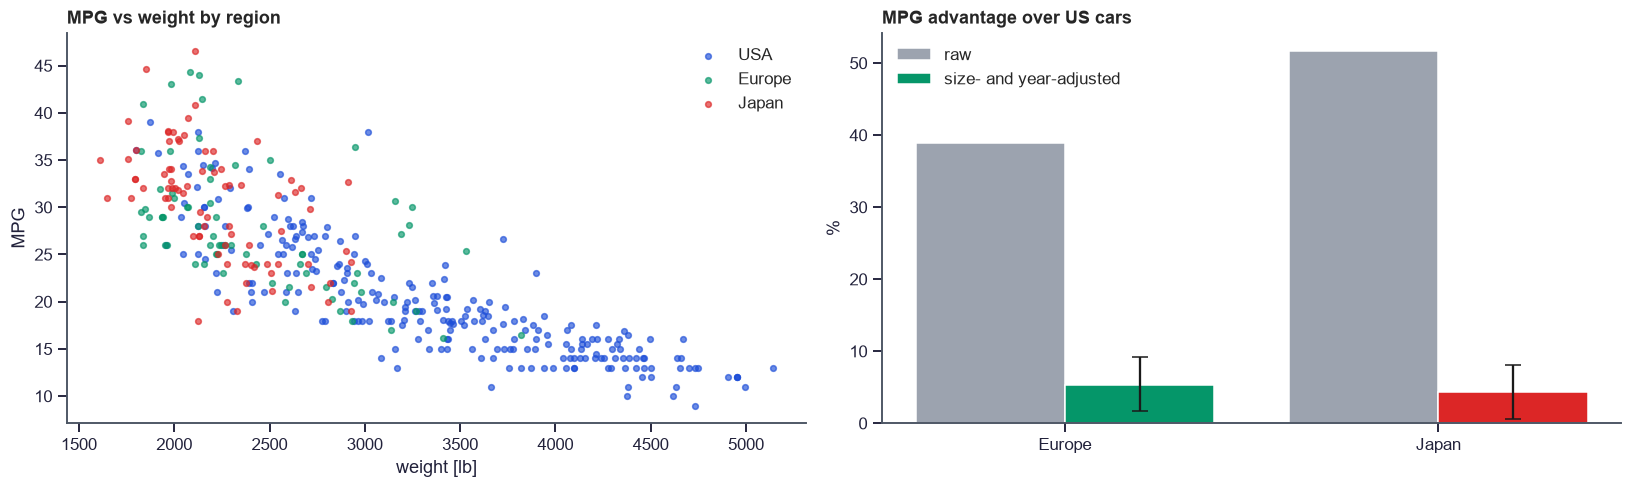

> **What we learn · domain.** Raw MPG advantage over US cars: Europe +39% raw vs +5% at equal weight, power and year, Japan +52% raw vs +4% at equal weight, power and year. Most of the apparent regional advantage comes from car size, a classic case of confounding.

In [11]:
reg_df = cars.dropna(subset=["horsepower"]).copy()
Xr = np.column_stack([np.log(reg_df["weight"]), np.log(reg_df["horsepower"]), reg_df["year"],
                      (reg_df["region"] == "Europe").astype(float), (reg_df["region"] == "Japan").astype(float)])
b_r, se_r, _, _ = ols(Xr, np.log(reg_df["gpm"]).to_numpy())
usa_mpg = cars.loc[cars["region"] == "USA", "mpg"].mean()
origin = []
for i, region in [(4, "Europe"), (5, "Japan")]:
    raw_gap = cars.loc[cars["region"] == region, "mpg"].mean() / usa_mpg - 1
    adj = np.exp(-b_r[i]) - 1
    lo, hi = np.exp(-(b_r[i] + 1.96 * se_r[i])) - 1, np.exp(-(b_r[i] - 1.96 * se_r[i])) - 1
    origin.append({"region": region, "raw MPG advantage vs USA": raw_gap, "adjusted advantage": adj, "adjusted 95% CI low": lo,
                   "adjusted 95% CI high": hi, "share explained by car size": 1 - adj / raw_gap if raw_gap else np.nan})
origin = pd.DataFrame(origin).set_index("region")
display(origin.style.format("{:+.1%}"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for r, c in REGION_COLORS.items():
    s = cars[cars["region"] == r]
    axes[0].scatter(s["weight"], s["mpg"], s=14, alpha=0.65, color=c, label=r)
axes[0].set(title="MPG vs weight by region", xlabel="weight [lb]", ylabel="MPG")
axes[0].legend()
x = np.arange(len(origin))
axes[1].bar(x - 0.2, origin["raw MPG advantage vs USA"] * 100, 0.4, color=GREY, label="raw")
axes[1].bar(x + 0.2, origin["adjusted advantage"] * 100, 0.4, color=[REGION_COLORS[r] for r in origin.index], label="size- and year-adjusted",
            yerr=[(origin["adjusted advantage"] - origin["adjusted 95% CI low"]) * 100,
                  (origin["adjusted 95% CI high"] - origin["adjusted advantage"]) * 100], capsize=5)
axes[1].set_xticks(x, origin.index)
axes[1].axhline(0, c=INK, lw=0.8)
axes[1].set(title="MPG advantage over US cars", ylabel="%")
axes[1].legend()
fig.tight_layout()
savefig(fig, "3_4_origin")
plt.show()

learn("domain", "Raw MPG advantage over US cars: " + ", ".join(
    f"{r} {origin.loc[r, 'raw MPG advantage vs USA']:+.0%} raw vs {origin.loc[r, 'adjusted advantage']:+.0%} at equal weight, power and year"
    for r in origin.index) + (". Most of the apparent regional advantage comes from car size, a classic case of confounding."
    if (origin["share explained by car size"] > 0.5).all() else
    ". Part of the raw gap is explained by car size, but a substantial regional difference remains after adjustment."))

### 3.5 Diesel engines: an efficiency effect the numeric inputs cannot see
Using the same size-and-year model as in §3.4, each car's fuel consumption is compared with the value expected for its weight, power and year. If diesel cars sit systematically below the expectation, a model without a diesel flag will underestimate their MPG. Those cars would then show up as the largest errors.

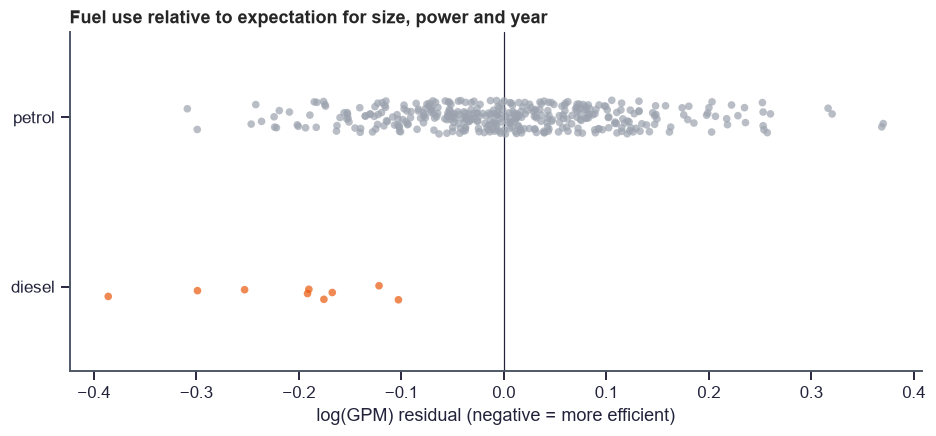

> **What we learn · domain.** Diesel cars use about 19% less fuel than petrol cars of the same weight, power and year. The numeric inputs cannot express this, so the diesel flag taken from the names adds new information.

In [12]:
resid_df = reg_df.assign(expected_log_gpm=np.column_stack([np.ones(len(reg_df)), Xr]) @ b_r)
resid_df["log_gpm_residual"] = np.log(resid_df["gpm"]) - resid_df["expected_log_gpm"]
diesel_effect = resid_df.groupby("diesel")["log_gpm_residual"].mean()
diesel_saving = 1 - np.exp(diesel_effect.get(1, np.nan) - diesel_effect.get(0, 0))

fig, ax = plt.subplots(figsize=(10, 4))
sns.stripplot(data=resid_df.assign(engine=resid_df["diesel"].map({0: "petrol", 1: "diesel"})), x="log_gpm_residual", y="engine",
              hue="engine", palette={"petrol": GREY, "diesel": ORANGE}, size=5, alpha=0.7, ax=ax, legend=False)
ax.axvline(0, c=INK, lw=0.8)
ax.set(title="Fuel use relative to expectation for size, power and year", xlabel="log(GPM) residual (negative = more efficient)", ylabel="")
savefig(fig, "3_5_diesel")
plt.show()
learn("domain", f"Diesel cars use about {diesel_saving:.0%} less fuel than petrol cars of the same weight, power and year. "
      + ("The numeric inputs cannot express this, so the diesel flag taken from the names adds new information."
         if diesel_saving > 0.05 else "The difference is small, so the diesel flag adds little beyond the numeric inputs."))

## 4 · Validation Design and Baseline

- **Hold-out:** a random 20 % test set is kept aside, using the same seed as the original analysis so the results can be compared. It is used once, in §7.
- **Model comparison:** 5-fold cross-validation repeated 5 times on the training set. Repeating the folds makes the average error more stable, and each model's spread across repeats shows how much its score depends on the particular split.
- **Missing values, scaling and encoding** are all done inside the model pipeline, so they are recomputed from the training part of every fold.
- **Metric:** RMSE in MPG. All models are scored in MPG, including those trained on GPM.

In [13]:
RAW_INPUTS = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "year", "region", "diesel", "wagon"]
train_df, test_df = train_test_split(cars, test_size=CONFIG["test_size"], random_state=SEED, shuffle=True)
X_train, y_train, X_test, y_test = train_df[RAW_INPUTS], train_df["mpg"], test_df[RAW_INPUTS], test_df["mpg"]
RCV = RepeatedKFold(n_splits=CONFIG["cv_splits"], n_repeats=CONFIG["cv_repeats"], random_state=SEED)

baseline_rmse = rmse(y_test, np.full(len(y_test), y_train.mean()))
display(pd.DataFrame({"cars": [len(train_df), len(test_df)], "mean MPG": [y_train.mean(), y_test.mean()],
                      "diesels": [train_df["diesel"].sum(), test_df["diesel"].sum()]}, index=["train", "test"]).style.format(precision=2))
print(f"Baseline (predict training mean): test RMSE = {baseline_rmse:.3f} MPG")

,cars,mean MPG,diesels
train,318,23.61,9
test,80,23.14,0


Baseline (predict training mean): test RMSE = 7.347 MPG


## 5 · Model Benchmark

### 5.1 Feature sets
| Set | Inputs |
|---|---|
| **original** | cylinders, displacement, horsepower, weight, acceleration, year, region (as in the original project) |
| **engineered** | original + diesel, wagon, log(weight), power-to-weight ratio, displacement per cylinder |

Engineered features are computed inside the pipeline from the raw inputs. This keeps them consistent when an input is changed later, for example in the permutation importance of §9.

In [14]:
def engineer(df, feature_set="engineered"):
    out = df[["cylinders", "displacement", "horsepower", "weight", "acceleration", "year", "region"]].copy()
    if feature_set == "engineered":
        out["diesel"] = df["diesel"]
        out["wagon"] = df["wagon"]
        out["log_weight"] = np.log(df["weight"])
        out["power_to_weight"] = df["horsepower"] / df["weight"] * 1000
        out["disp_per_cyl"] = df["displacement"] / df["cylinders"]
    return out


def numeric_cols(feature_set):
    return [c for c in engineer(cars.head(), feature_set).columns if c != "region"]


FEATURE_SETS = ["original", "engineered"]
for fs in FEATURE_SETS:
    print(f"{fs:<11}: {', '.join(engineer(cars.head(), fs).columns)}")

original   : cylinders, displacement, horsepower, weight, acceleration, year, region
engineered : cylinders, displacement, horsepower, weight, acceleration, year, region, diesel, wagon, log_weight, power_to_weight, disp_per_cyl


### 5.2 Model library
Fifteen models, ordered roughly from simplest to most flexible. This order is used later by the one-standard-error rule, which picks the simplest model whose score is statistically indistinguishable from the best.

| Key | Model | Idea |
|---|---|---|
| MEAN | Mean predictor | baseline |
| OLS | Linear regression | additive linear effects |
| RIDGE / LASSO / ENET | Regularised linear | shrinkage / variable selection |
| OLS_GPM | Linear regression on GPM | physically motivated: fuel use is linear in size |
| LOG_OLS | Linear regression on log MPG | multiplicative effects |
| SPLINE | Ridge on cubic-spline basis | smooth nonlinear additive effects |
| KNN | k-nearest neighbours | local averaging |
| SVR | Support vector regression (RBF) | kernel smoother |
| GP | Gaussian process (ARD RBF) | Bayesian kernel smoother |
| RF | Random forest | bagged trees (original champion) |
| GBR / XGB / LGBM | Gradient boosting | boosted trees |
| MLP | Neural network | universal approximator |

In [15]:
def to_gpm(y):
    return 100.0 / np.asarray(y)


def from_gpm(g):
    return 100.0 / np.asarray(g)


MODEL_NAMES = {"MEAN": "Mean baseline", "OLS": "Linear regression", "RIDGE": "Ridge", "LASSO": "Lasso", "ENET": "Elastic Net",
               "OLS_GPM": "Linear on GPM (physics)", "LOG_OLS": "Linear on log MPG", "SPLINE": "Spline additive (ridge)",
               "KNN": "k-NN", "SVR": "SVR (RBF)", "GP": "Gaussian process", "RF": "Random forest", "GBR": "Gradient boosting",
               "XGB": "XGBoost", "LGBM": "LightGBM", "MLP": "MLP"}
COMPLEXITY = list(MODEL_NAMES)
FAMILY = {"MEAN": "baseline", "OLS": "linear", "RIDGE": "linear", "LASSO": "linear", "ENET": "linear", "OLS_GPM": "linear",
          "LOG_OLS": "linear", "SPLINE": "additive", "KNN": "local", "SVR": "kernel", "GP": "kernel", "RF": "trees",
          "GBR": "trees", "XGB": "trees", "LGBM": "trees", "MLP": "neural"}
FAMILY_COLORS = {"baseline": GREY, "linear": "#0369A1", "additive": TEAL, "local": "#B45309", "kernel": PLUM,
                 "trees": ORANGE, "neural": "#BE123C"}


def make_prep(feature_set, spline=False):
    num = numeric_cols(feature_set)
    num_pipe = [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
    if spline:
        num_pipe.append(("spline", SplineTransformer(n_knots=5, degree=3)))
    return ColumnTransformer([("num", Pipeline(num_pipe), num),
                              ("region", OneHotEncoder(drop="first", handle_unknown="ignore"), ["region"])])


def make_estimator(key, n_features):
    scaled = lambda est: TransformedTargetRegressor(regressor=est, transformer=StandardScaler())
    return {
        "MEAN": lambda: DummyRegressor(),
        "OLS": lambda: LinearRegression(),
        "RIDGE": lambda: Ridge(alpha=1.0),
        "LASSO": lambda: Lasso(alpha=0.05, max_iter=50000),
        "ENET": lambda: ElasticNet(alpha=0.05, l1_ratio=0.5, max_iter=50000),
        "OLS_GPM": lambda: TransformedTargetRegressor(regressor=LinearRegression(), func=to_gpm, inverse_func=from_gpm, check_inverse=False),
        "LOG_OLS": lambda: TransformedTargetRegressor(regressor=LinearRegression(), func=np.log, inverse_func=np.exp, check_inverse=False),
        "SPLINE": lambda: Ridge(alpha=1.0),
        "KNN": lambda: KNeighborsRegressor(n_neighbors=7, weights="distance"),
        "SVR": lambda: scaled(SVR(C=10.0, epsilon=0.05, gamma="scale")),
        "GP": lambda: GaussianProcessRegressor(ConstantKernel(1.0) * RBF(np.ones(n_features), (1e-2, 1e3)) + WhiteKernel(0.1, (1e-5, 1)),
                                               normalize_y=True, n_restarts_optimizer=1, random_state=SEED),
        "RF": lambda: RandomForestRegressor(n_estimators=400, random_state=SEED, n_jobs=1),
        "GBR": lambda: GradientBoostingRegressor(random_state=SEED),
        "XGB": lambda: XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=3, subsample=0.9, n_jobs=1, random_state=SEED),
        "LGBM": lambda: LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=15, min_child_samples=5, n_jobs=1,
                                      random_state=SEED, verbose=-1),
        "MLP": lambda: scaled(MLPRegressor(hidden_layer_sizes=(32, 16), alpha=1e-3, max_iter=5000, random_state=SEED)),
    }[key]()


def build(key, feature_set="engineered"):
    prep = make_prep(feature_set, spline=(key == "SPLINE"))
    n_features = len(numeric_cols(feature_set)) + 2
    return Pipeline([("features", FunctionTransformer(engineer, kw_args={"feature_set": feature_set})),
                     ("prep", prep), ("model", make_estimator(key, n_features))])


def model_prefix(key):
    return "model__regressor__" if key in ("SVR", "MLP") else "model__"

### 5.3 Repeated cross-validation
Every model is run on both feature sets. The figure shows the distribution of RMSE across the repeated folds. The table adds each model's gap to the best model, tested with the Nadeau–Bengio corrected t-test. The correction is needed because CV training sets overlap, which makes a naive t-test far too confident.

In [16]:
def corrected_test(a, b, n_train, n_test, k):
    d = np.asarray(a) - np.asarray(b)
    se = np.sqrt((1 / k + n_test / n_train) * d.var(ddof=1))
    return (d.mean(), 2 * stats.t.sf(abs(d.mean() / se), k - 1)) if se > 0 else (d.mean(), np.nan)


n_test_fold = len(X_train) / CONFIG["cv_splits"]
n_train_fold = len(X_train) - n_test_fold
bench, fold_scores = [], {}
t0 = time.time()
for fs in FEATURE_SETS:
    for key in MODEL_NAMES:
        res = cross_validate(build(key, fs), X_train, y_train, cv=RCV, n_jobs=-1,
                             scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"})
        fold_scores[(fs, key)] = -res["test_rmse"]
        bench.append({"feature_set": fs, "model": key, "RMSE": -res["test_rmse"].mean(), "RMSE sd": res["test_rmse"].std(),
                      "MAE": -res["test_mae"].mean(), "R²": res["test_r2"].mean()})
print(f"Benchmark finished in {time.time() - t0:.0f} s")
bench = pd.DataFrame(bench)
best_key = bench.loc[bench["RMSE"].idxmin(), ["feature_set", "model"]].tolist()
k_folds = len(fold_scores[tuple(best_key)])
bench["Δ vs best"], bench["p (corrected)"] = zip(*[
    corrected_test(fold_scores[(r.feature_set, r.model)], fold_scores[tuple(best_key)], n_train_fold, n_test_fold, k_folds)
    if (r.feature_set, r.model) != tuple(best_key) else (0.0, np.nan) for r in bench.itertuples()])
bench["name"] = bench["model"].map(MODEL_NAMES)
savetab(bench, "5_3_benchmark")
display(bench.pivot(index="name", columns="feature_set", values="RMSE")
        .sort_values("engineered").style.format(precision=3).background_gradient(cmap="YlGn_r"))

Benchmark finished in 711 s


feature_set,engineered,original
name,,
Spline additive (ridge),2.610,2.843
XGBoost,2.681,2.852
Gaussian process,2.706,2.900
Gradient boosting,2.767,2.897
Linear on log MPG,2.772,3.091
MLP,2.805,2.889
SVR (RBF),2.811,2.827
k-NN,2.812,3.021
LightGBM,2.817,3.026


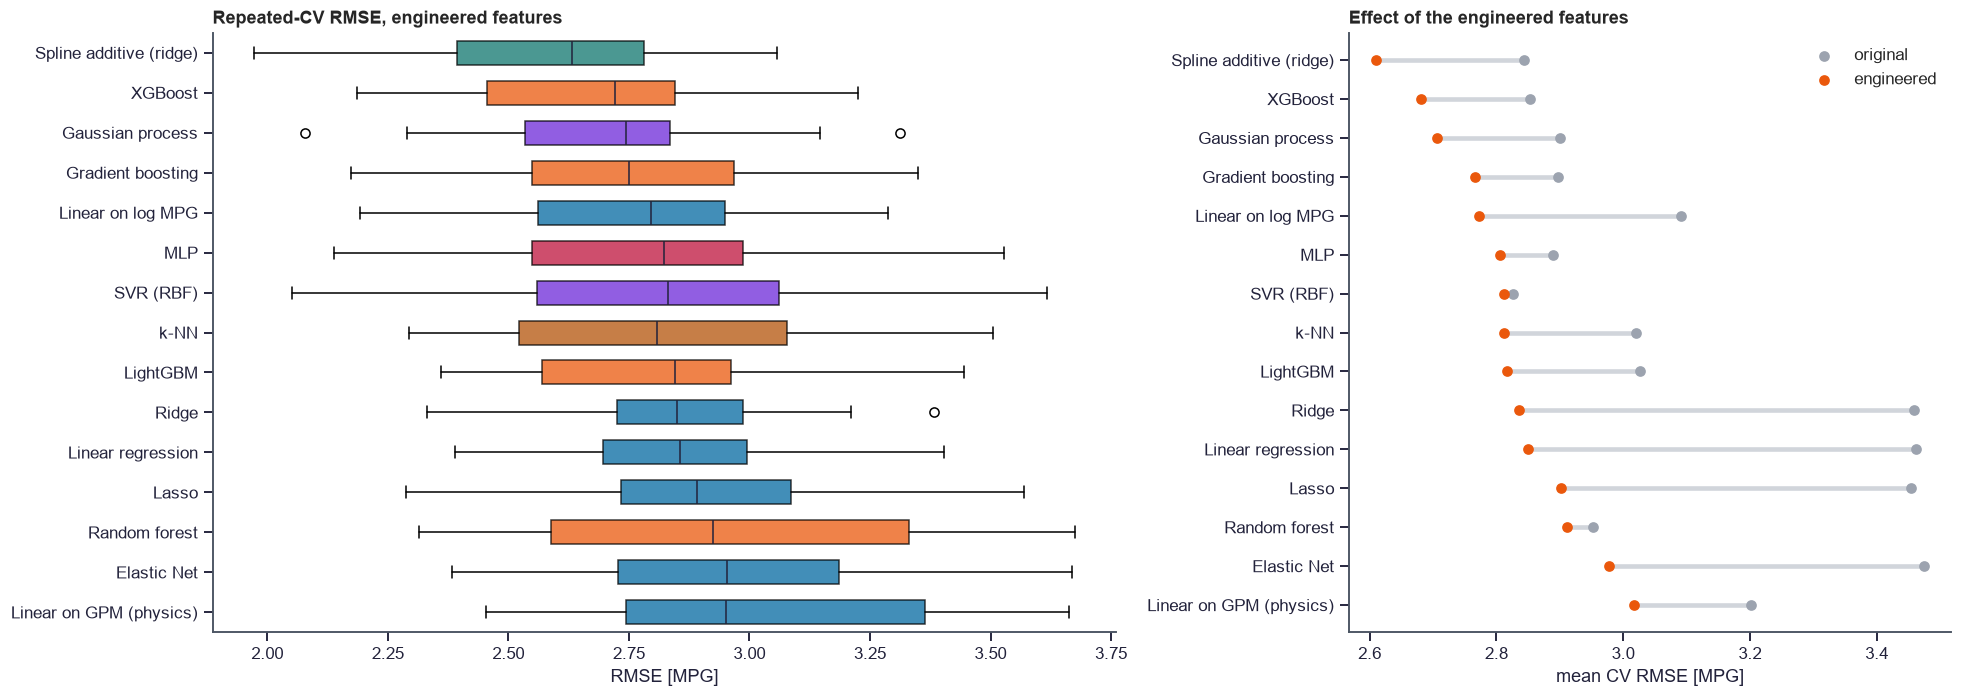

In [17]:
eng = bench[bench["feature_set"] == "engineered"].sort_values("RMSE")
order = eng["model"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})
data = [fold_scores[("engineered", k)] for k in order if k != "MEAN"]
labels = [MODEL_NAMES[k] for k in order if k != "MEAN"]
bp = axes[0].boxplot(data, vert=False, patch_artist=True, widths=0.6, medianprops={"color": INK})
for patch, k in zip(bp["boxes"], [k for k in order if k != "MEAN"]):
    patch.set_facecolor(FAMILY_COLORS[FAMILY[k]])
    patch.set_alpha(0.75)
axes[0].set_yticks(range(1, len(labels) + 1), labels)
axes[0].invert_yaxis()
axes[0].set(title="Repeated-CV RMSE, engineered features", xlabel="RMSE [MPG]")

piv = bench.pivot(index="model", columns="feature_set", values="RMSE").drop(index="MEAN").loc[[k for k in order if k != "MEAN"]]
axes[1].hlines(range(len(piv)), piv["engineered"], piv["original"], color="#D1D5DB", lw=3)
axes[1].scatter(piv["original"], range(len(piv)), color=GREY, label="original", zorder=3)
axes[1].scatter(piv["engineered"], range(len(piv)), color=ORANGE, label="engineered", zorder=3)
axes[1].set_yticks(range(len(piv)), [MODEL_NAMES[k] for k in piv.index])
axes[1].invert_yaxis()
axes[1].set(title="Effect of the engineered features", xlabel="mean CV RMSE [MPG]")
axes[1].legend()
fig.tight_layout()
savefig(fig, "5_3_benchmark")
plt.show()

In [18]:
fs_gain = (piv["original"] - piv["engineered"])
eng_i = eng.set_index("model")
best = eng_i.index[0]
se_best = eng_i.loc[best, "RMSE sd"] / np.sqrt(k_folds)
one_se = next(k for k in COMPLEXITY if k in eng_i.index and eng_i.loc[k, "RMSE"] <= eng_i.loc[best, "RMSE"] + se_best)
indist = eng_i[(eng_i["p (corrected)"] > 0.05) | (eng_i.index == best)].index.tolist()
display(eng_i[["name", "RMSE", "RMSE sd", "R²", "Δ vs best", "p (corrected)"]].style.format(precision=3))

learn("modelling", f"The best cross-validated model is {MODEL_NAMES[best]} (RMSE {eng_i.loc[best, 'RMSE']:.2f} MPG). "
      f"{len(indist)} models are statistically indistinguishable from it (corrected p > 0.05): {', '.join(MODEL_NAMES[k] for k in indist)}. "
      + (f"The one-standard-error rule selects the simpler {MODEL_NAMES[one_se]}." if one_se != best
         else "No simpler model comes within one standard error, so the one-standard-error rule keeps it."))
learn("modelling", f"The engineered features (diesel, wagon, log weight, ratios) lower CV RMSE for {int((fs_gain > 0).sum())} of {len(fs_gain)} models, "
      f"by {fs_gain.median():.2f} MPG at the median and by up to {fs_gain.max():.2f} MPG ({MODEL_NAMES[fs_gain.idxmax()]}). "
      f"The physics-motivated linear model on GPM reaches {eng_i.loc['OLS_GPM', 'RMSE']:.2f} MPG, compared with {eng_i.loc['OLS', 'RMSE']:.2f} for the same model on MPG"
      + (", so changing the target scale alone improves the linear model." if eng_i.loc['OLS_GPM', 'RMSE'] < eng_i.loc['OLS', 'RMSE']
         else ", so the target transformation does not help the linear model here."))

,name,RMSE,RMSE sd,R²,Δ vs best,p (corrected)
model,,,,,,
SPLINE,Spline additive (ridge),2.610,0.274,0.888,0.000,nan
XGB,XGBoost,2.681,0.284,0.881,0.071,0.591
GP,Gaussian process,2.706,0.268,0.879,0.096,0.220
GBR,Gradient boosting,2.767,0.289,0.874,0.157,0.186
LOG_OLS,Linear on log MPG,2.772,0.281,0.874,0.162,0.126
MLP,MLP,2.805,0.316,0.870,0.195,0.063
SVR,SVR (RBF),2.811,0.343,0.869,0.201,0.140
KNN,k-NN,2.812,0.330,0.869,0.202,0.049
LGBM,LightGBM,2.817,0.298,0.869,0.207,0.145


> **What we learn · modelling.** The best cross-validated model is Spline additive (ridge) (RMSE 2.61 MPG). 9 models are statistically indistinguishable from it (corrected p > 0.05): Spline additive (ridge), XGBoost, Gaussian process, Gradient boosting, Linear on log MPG, MLP, SVR (RBF), LightGBM, Random forest. No simpler model comes within one standard error, so the one-standard-error rule keeps it.

> **What we learn · modelling.** The engineered features (diesel, wagon, log weight, ratios) lower CV RMSE for 15 of 15 models, by 0.21 MPG at the median and by up to 0.62 MPG (Ridge). The physics-motivated linear model on GPM reaches 3.02 MPG, compared with 2.85 for the same model on MPG, so the target transformation does not help the linear model here.

## 6 · Hyperparameter Tuning
Every model with hyperparameters is tuned by a randomised search over repeated 5-fold CV on the engineered feature set. The comparison of default and tuned scores shows how much tuning adds on a dataset of this size.

In [19]:
SPACES = {
    "RIDGE": {"alpha": loguniform(1e-3, 1e3)},
    "LASSO": {"alpha": loguniform(1e-4, 2)},
    "ENET": {"alpha": loguniform(1e-4, 2), "l1_ratio": uniform(0.05, 0.9)},
    "SPLINE": {"alpha": loguniform(1e-3, 1e3)},
    "KNN": {"n_neighbors": randint(2, 30), "weights": ["uniform", "distance"], "p": [1, 2]},
    "SVR": {"C": loguniform(0.1, 1000), "epsilon": loguniform(1e-3, 0.5), "gamma": loguniform(1e-3, 1)},
    "RF": {"n_estimators": randint(200, 800), "max_depth": [None, 4, 6, 10, 16], "min_samples_leaf": randint(1, 8),
           "max_features": [0.33, 0.5, 0.8, 1.0]},
    "GBR": {"n_estimators": randint(100, 800), "learning_rate": loguniform(0.01, 0.3), "max_depth": randint(2, 6),
            "subsample": uniform(0.6, 0.4), "min_samples_leaf": randint(1, 15)},
    "XGB": {"n_estimators": randint(100, 900), "learning_rate": loguniform(0.01, 0.3), "max_depth": randint(2, 7),
            "min_child_weight": loguniform(0.5, 10), "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5),
            "reg_lambda": loguniform(1e-2, 10)},
    "LGBM": {"n_estimators": randint(100, 900), "learning_rate": loguniform(0.01, 0.3), "num_leaves": randint(4, 32),
             "min_child_samples": randint(3, 30), "subsample": uniform(0.6, 0.4), "subsample_freq": [1],
             "colsample_bytree": uniform(0.5, 0.5), "reg_lambda": loguniform(1e-3, 10)},
    "MLP": {"hidden_layer_sizes": [(16,), (32,), (32, 16), (64, 32)], "alpha": loguniform(1e-5, 1),
            "learning_rate_init": loguniform(1e-4, 1e-2)},
}
TUNE_CV = RepeatedKFold(n_splits=5, n_repeats=2, random_state=SEED)
tuned, tune_rows = {}, []
for key in MODEL_NAMES:
    pipe = build(key, "engineered")
    if key in SPACES:
        search = RandomizedSearchCV(pipe, {model_prefix(key) + k: v for k, v in SPACES[key].items()},
                                    n_iter=CONFIG["search_iter"], cv=TUNE_CV, scoring="neg_root_mean_squared_error",
                                    n_jobs=-1, random_state=SEED)
        search.fit(X_train, y_train)
        tuned[key], cv_rmse = search.best_estimator_, -search.best_score_
        params = {k.split("__")[-1]: (round(v, 4) if isinstance(v, float) else v) for k, v in search.best_params_.items()}
    else:
        tuned[key] = pipe.fit(X_train, y_train)
        cv_rmse, params = eng_i.loc[key, "RMSE"], {}
    tune_rows.append({"model": MODEL_NAMES[key], "key": key, "default CV RMSE": eng_i.loc[key, "RMSE"], "tuned CV RMSE": cv_rmse,
                      "parameters": params})
tuning = pd.DataFrame(tune_rows).set_index("model")
tuning["gain"] = tuning["default CV RMSE"] - tuning["tuned CV RMSE"]
display(tuning.sort_values("tuned CV RMSE").style.format(precision=3, subset=["default CV RMSE", "tuned CV RMSE", "gain"]))
savetab(tuning, "6_tuning")
CHAMPION = tuning.sort_values("tuned CV RMSE")["key"].iloc[0]
gained = tuning[tuning["key"].isin(SPACES)]["gain"]
learn("modelling", f"Tuning improved CV RMSE by {gained.median():.3f} MPG at the median, and by at most {gained.max():.2f} MPG "
      f"({gained.idxmax()}), compared with a median gain of {fs_gain.median():.3f} MPG from the engineered features. "
      + ("On this dataset, better features matter more than hyperparameter search. " if fs_gain.median() > gained.median()
         else "On this dataset, tuning contributes more than the extra features. ")
      + f"The champion after tuning is {MODEL_NAMES[CHAMPION]}.")

,key,default CV RMSE,tuned CV RMSE,parameters,gain
model,,,,,
Spline additive (ridge),SPLINE,2.610,2.523,{'alpha': np.float64(0.1578)},0.087
XGBoost,XGB,2.681,2.662,"{'colsample_bytree': np.float64(0.6221), 'learning_rate': np.float64(0.0177), 'max_depth': 2, 'min_child_weight': np.float64(1.6764), 'n_estimators': 596, 'reg_lambda': np.float64(0.0578), 'subsample': np.float64(0.6988)}",0.019
MLP,MLP,2.805,2.682,"{'alpha': np.float64(0.0001), 'hidden_layer_sizes': (64, 32), 'learning_rate_init': np.float64(0.0008)}",0.124
Gaussian process,GP,2.706,2.706,{},0.000
Gradient boosting,GBR,2.767,2.728,"{'learning_rate': np.float64(0.0785), 'max_depth': 3, 'min_samples_leaf': 7, 'n_estimators': 140, 'subsample': np.float64(0.966)}",0.039
LightGBM,LGBM,2.817,2.769,"{'colsample_bytree': np.float64(0.5853), 'learning_rate': np.float64(0.0125), 'min_child_samples': 6, 'n_estimators': 700, 'num_leaves': 31, 'reg_lambda': np.float64(0.1791), 'subsample': np.float64(0.7542), 'subsample_freq': 1}",0.048
Linear on log MPG,LOG_OLS,2.772,2.772,{},0.000
SVR (RBF),SVR,2.811,2.777,"{'C': np.float64(1.6537), 'epsilon': np.float64(0.0018), 'gamma': np.float64(0.1129)}",0.034
k-NN,KNN,2.812,2.803,"{'n_neighbors': 7, 'p': 2, 'weights': 'distance'}",0.009


> **What we learn · modelling.** Tuning improved CV RMSE by 0.039 MPG at the median, and by at most 0.15 MPG (Elastic Net), compared with a median gain of 0.209 MPG from the engineered features. On this dataset, better features matter more than hyperparameter search. The champion after tuning is Spline additive (ridge).

## 7 · Hold-out Evaluation

### 7.1 Test-set performance
Every tuned model is scored once on the 80 test cars. A bootstrap 95 % confidence interval for RMSE shows how precisely 80 cars can measure performance. The original project reported a test RMSE of 2.27 MPG for its random forest on this same split.

In [20]:
def boot_rmse(y, p, n=CONFIG["bootstrap"]):
    r = np.random.default_rng(SEED)
    y, p = np.asarray(y), np.asarray(p)
    idx = r.integers(0, len(y), (n, len(y)))
    return np.percentile(np.sqrt(((y[idx] - p[idx]) ** 2).mean(axis=1)), [2.5, 97.5])


pred_test = {k: m.predict(X_test) for k, m in tuned.items()}
rows = []
for k, p in pred_test.items():
    lo, hi = boot_rmse(y_test, p)
    rows.append({"model": MODEL_NAMES[k], "key": k, "family": FAMILY[k], "RMSE": rmse(y_test, p), "RMSE 95% CI": f"{lo:.2f}–{hi:.2f}",
                 "MAE": mean_absolute_error(y_test, p), "R²": r2_score(y_test, p),
                 "MAPE %": 100 * np.mean(np.abs((y_test - p) / y_test))})
holdout = pd.DataFrame(rows).set_index("model").sort_values("RMSE")
display(holdout.drop(columns="key").style.format(precision=3).background_gradient(subset=["RMSE"], cmap="YlGn_r"))
savetab(holdout, "7_1_holdout")
champ_row = holdout[holdout["key"] == CHAMPION].iloc[0]
learn("modelling", f"On the hold-out set, {MODEL_NAMES[CHAMPION]} reaches RMSE {champ_row['RMSE']:.2f} MPG (95% CI {champ_row['RMSE 95% CI']}), "
      f"against {baseline_rmse:.2f} for the mean baseline. The width of that interval shows that 80 test cars cannot separate "
      f"models whose errors differ by a few tenths of an MPG.")

,family,RMSE,RMSE 95% CI,MAE,R²,MAPE %
model,,,,,,
Random forest,trees,2.041,1.66–2.38,1.561,0.922,7.121
LightGBM,trees,2.285,1.77–2.81,1.603,0.903,7.094
XGBoost,trees,2.314,1.80–2.85,1.709,0.900,7.775
Gaussian process,kernel,2.321,1.81–2.88,1.710,0.900,7.764
Gradient boosting,trees,2.364,1.90–2.84,1.798,0.896,8.112
Linear on log MPG,linear,2.400,1.86–2.98,1.723,0.893,7.707
Spline additive (ridge),additive,2.422,1.95–2.85,1.866,0.891,8.451
Ridge,linear,2.478,1.95–3.05,1.824,0.886,8.273
Elastic Net,linear,2.478,1.95–3.06,1.825,0.886,8.278


> **What we learn · modelling.** On the hold-out set, Spline additive (ridge) reaches RMSE 2.42 MPG (95% CI 1.95–2.85), against 7.35 for the mean baseline. The width of that interval shows that 80 test cars cannot separate models whose errors differ by a few tenths of an MPG.

### 7.2 Where the errors are
Residuals are examined on both scales. On the MPG scale, larger errors for efficient cars (the pattern noted in the original evaluation) are expected: an error of a fixed size in fuel use becomes a larger error in MPG when MPG is high, because $\partial MPG/\partial GPM = -MPG^2/100$. If the residuals are even on the GPM scale, that pattern follows from the choice of measurement scale and is not a flaw of the model.

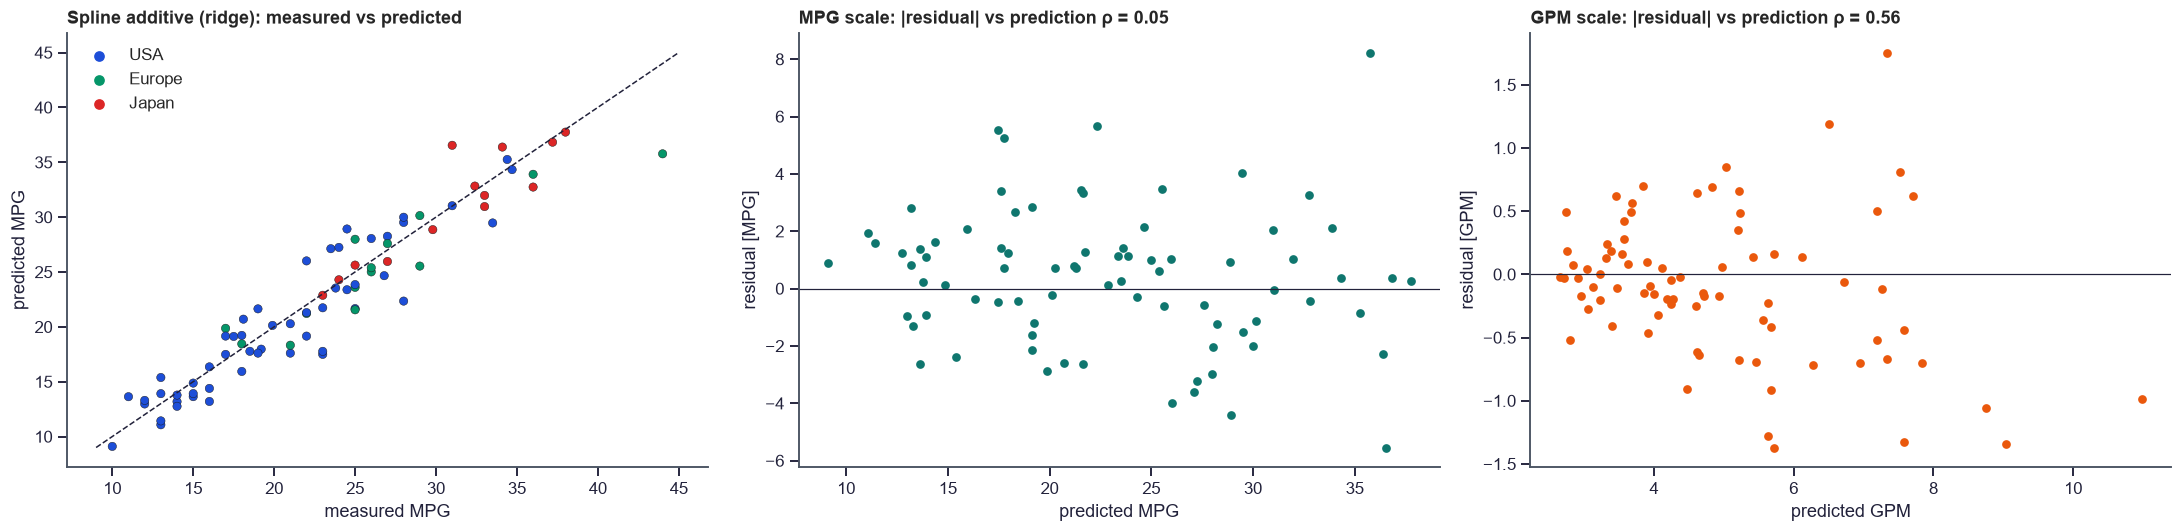

,name,year,region,weight,horsepower,diesel,mpg,predicted,error
394,vw pickup,1982,Europe,2130,52.0,0,44.0,35.8,8.2
30,chevrolet vega 2300,1971,USA,2264,90.0,0,28.0,22.3,5.7
377,mazda glc custom,1982,Japan,1970,68.0,0,31.0,36.5,-5.5
298,cadillac eldorado,1979,USA,3900,125.0,0,23.0,17.5,5.5
101,plymouth duster,1973,USA,2904,95.0,0,23.0,17.8,5.2
196,chevrolet woody,1976,USA,2164,60.0,0,24.5,28.9,-4.4
238,dodge colt m/m,1977,USA,2075,83.0,0,33.5,29.5,4.0
389,ford granada l,1982,USA,2835,112.0,0,22.0,26.0,-4.0


region,Europe,Japan,USA
MAE by region,2.27,1.40,1.87


> **What we learn · modelling.** The correlation between error size and predicted value is 0.05 on the MPG scale and 0.56 on the GPM scale. The pattern remains on the GPM scale, so the model is less accurate for some cars for reasons other than the measurement scale.

In [21]:
p = pred_test[CHAMPION]
res_mpg = y_test - p
res_gpm = 100 / y_test - 100 / p
rho_mpg = stats.spearmanr(p, np.abs(res_mpg)).statistic
rho_gpm = stats.spearmanr(100 / p, np.abs(res_gpm)).statistic

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sc = axes[0].scatter(y_test, p, c=test_df["region"].map(REGION_COLORS), s=30, edgecolor="k", lw=0.3)
lim = [y_test.min() - 1, y_test.max() + 1]
axes[0].plot(lim, lim, "--", c=INK, lw=1)
axes[0].set(title=f"{MODEL_NAMES[CHAMPION]}: measured vs predicted", xlabel="measured MPG", ylabel="predicted MPG")
for r, c in REGION_COLORS.items():
    axes[0].scatter([], [], color=c, label=r)
axes[0].legend()
axes[1].scatter(p, res_mpg, s=22, color=TEAL)
axes[1].axhline(0, c=INK, lw=0.8)
axes[1].set(title=f"MPG scale: |residual| vs prediction ρ = {rho_mpg:.2f}", xlabel="predicted MPG", ylabel="residual [MPG]")
axes[2].scatter(100 / p, res_gpm, s=22, color=ORANGE)
axes[2].axhline(0, c=INK, lw=0.8)
axes[2].set(title=f"GPM scale: |residual| vs prediction ρ = {rho_gpm:.2f}", xlabel="predicted GPM", ylabel="residual [GPM]")
fig.tight_layout()
savefig(fig, "7_2_residuals")
plt.show()

worst = test_df.assign(predicted=p, error=res_mpg).reindex(res_mpg.abs().sort_values(ascending=False).index)
display(worst[["name", "year", "region", "weight", "horsepower", "diesel", "mpg", "predicted", "error"]].head(8).style.format(precision=1))
seg = test_df.assign(abs_err=np.abs(res_mpg)).groupby("region")["abs_err"].mean().rename("MAE by region")
display(seg.to_frame().T.style.format(precision=2))
learn("modelling", f"The correlation between error size and predicted value is {rho_mpg:.2f} on the MPG scale and {rho_gpm:.2f} on the GPM scale. "
      + ("The larger errors for economical cars largely follow from measuring efficiency as distance per gallon: "
         "a fixed accuracy in fuel use necessarily shows up as larger MPG errors when MPG is high."
         if rho_gpm < rho_mpg - 0.1 else
         "The pattern remains on the GPM scale, so the model is less accurate for some cars for reasons other than the measurement scale."))

## 8 · Robustness

### 8.1 How much does the split matter?
The original project's conclusions rest on a single 80-car test set. Here the whole procedure is repeated on `robustness_splits` different random splits. Each time, four representative models with their tuned settings are refitted on the new training set and scored on the new test set. The distribution of test RMSE, and how often each model wins, show how much a single reported number can be trusted.

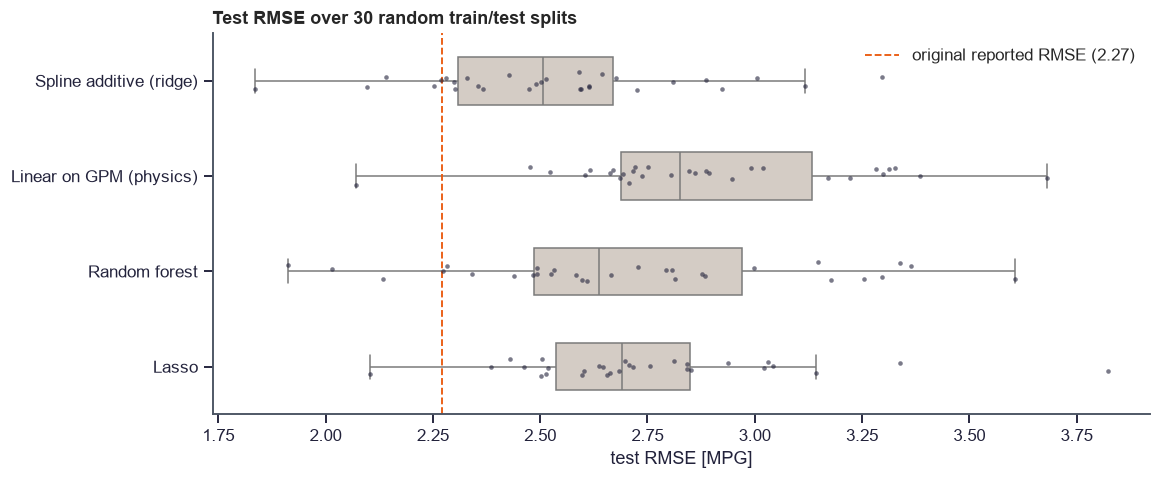

,mean,std,min,max,win_rate
model,,,,,
Lasso,2.749,0.323,2.104,3.822,3%
Linear on GPM (physics),2.885,0.334,2.072,3.682,0%
Random forest,2.715,0.421,1.913,3.606,30%
Spline additive (ridge),2.534,0.314,1.836,3.296,67%


> **What we learn · process.** Across 30 random splits, the random forest's test RMSE ranged from 1.91 to 3.61 MPG using the same method throughout. That spread of 1.69 MPG is the uncertainty attached to any single-split number such as 2.27. The most frequent winner was Spline additive (ridge) (67% of splits).

In [22]:
contenders = list(dict.fromkeys([CHAMPION, "OLS_GPM", "RF", "LASSO"]))
split_rows = []
for s in range(CONFIG["robustness_splits"]):
    tr, te = train_test_split(cars, test_size=CONFIG["test_size"], random_state=1000 + s)
    for k in contenders:
        m = clone(tuned[k]).fit(tr[RAW_INPUTS], tr["mpg"])
        split_rows.append({"split": s, "model": MODEL_NAMES[k], "RMSE": rmse(te["mpg"], m.predict(te[RAW_INPUTS]))})
splits = pd.DataFrame(split_rows)
wins = splits.loc[splits.groupby("split")["RMSE"].idxmin(), "model"].value_counts(normalize=True)
summary_split = splits.groupby("model")["RMSE"].agg(["mean", "std", "min", "max"]).assign(win_rate=wins).fillna({"win_rate": 0})

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=splits, x="RMSE", y="model", ax=ax, color=SAND, width=0.5, fliersize=0)
sns.stripplot(data=splits, x="RMSE", y="model", ax=ax, color=INK, size=3, alpha=0.6)
ax.axvline(2.27, ls="--", c=ORANGE, lw=1.2, label="original reported RMSE (2.27)")
ax.set(title=f"Test RMSE over {CONFIG['robustness_splits']} random train/test splits", xlabel="test RMSE [MPG]", ylabel="")
ax.legend()
savefig(fig, "8_1_split_variance")
plt.show()
display(summary_split.style.format(precision=3).format("{:.0%}", subset=["win_rate"]))
rf_range = summary_split.loc[MODEL_NAMES["RF"], ["min", "max"]]
learn("process", f"Across {CONFIG['robustness_splits']} random splits, the random forest's test RMSE ranged from {rf_range['min']:.2f} to {rf_range['max']:.2f} MPG "
      f"using the same method throughout. That spread of {rf_range['max'] - rf_range['min']:.2f} MPG is the uncertainty attached to any "
      f"single-split number such as 2.27. The most frequent winner was {wins.idxmax()} ({wins.max():.0%} of splits).")

### 8.2 The same car model in several years
Some car names occur in several model years (e.g. "ford pinto"). With random splitting, a car model can be in the training set in one year and in the test set in another. Grouped CV by car name measures how much this helps the models, and so how well they generalise to car models they have never seen.

In [23]:
groups = train_df["model_name"]
gk = GroupKFold(n_splits=CONFIG["cv_splits"])
kf = KFold(n_splits=CONFIG["cv_splits"], shuffle=True, random_state=SEED)
grp_rows = []
for k in contenders:
    r1 = -cross_validate(clone(tuned[k]), X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)["test_score"].mean()
    r2 = -cross_validate(clone(tuned[k]), X_train, y_train, cv=gk, groups=groups, scoring="neg_root_mean_squared_error", n_jobs=-1)["test_score"].mean()
    grp_rows.append({"model": MODEL_NAMES[k], "random KFold RMSE": r1, "grouped by car name RMSE": r2, "optimism": r2 - r1})
grp = pd.DataFrame(grp_rows).set_index("model")
display(grp.style.format(precision=3))
learn("process", f"Keeping every car name wholly in either training or validation changes CV RMSE by between {grp['optimism'].min():+.2f} and "
      f"{grp['optimism'].max():+.2f} MPG. Repeated car models make random-split scores {'slightly optimistic' if grp['optimism'].mean() > 0.05 else 'essentially unaffected'} "
      f"for this dataset.")

,random KFold RMSE,grouped by car name RMSE,optimism
model,,,
Spline additive (ridge),2.564,2.527,-0.037
Linear on GPM (physics),3.012,3.008,-0.004
Random forest,2.939,2.902,-0.036
Lasso,2.830,2.794,-0.036


> **What we learn · process.** Keeping every car name wholly in either training or validation changes CV RMSE by between -0.04 and -0.00 MPG. Repeated car models make random-split scores essentially unaffected for this dataset.

## 9 · Interpretation

### 9.1 Grouped permutation importance
Permuting one of several highly correlated inputs understates its importance, because the model can fall back on its correlated partners. The original analysis read impurity-based importances from the random forest, which are also biased towards continuous variables. Here the inputs are permuted **individually** and also as **groups** in which all members are shuffled together:

| Group | Inputs |
|---|---|
| size & power | cylinders, displacement, horsepower, weight |
| technology era | year |
| performance | acceleration |
| origin | region |
| engine & body type | diesel, wagon |

All derived features are recomputed from the shuffled inputs.

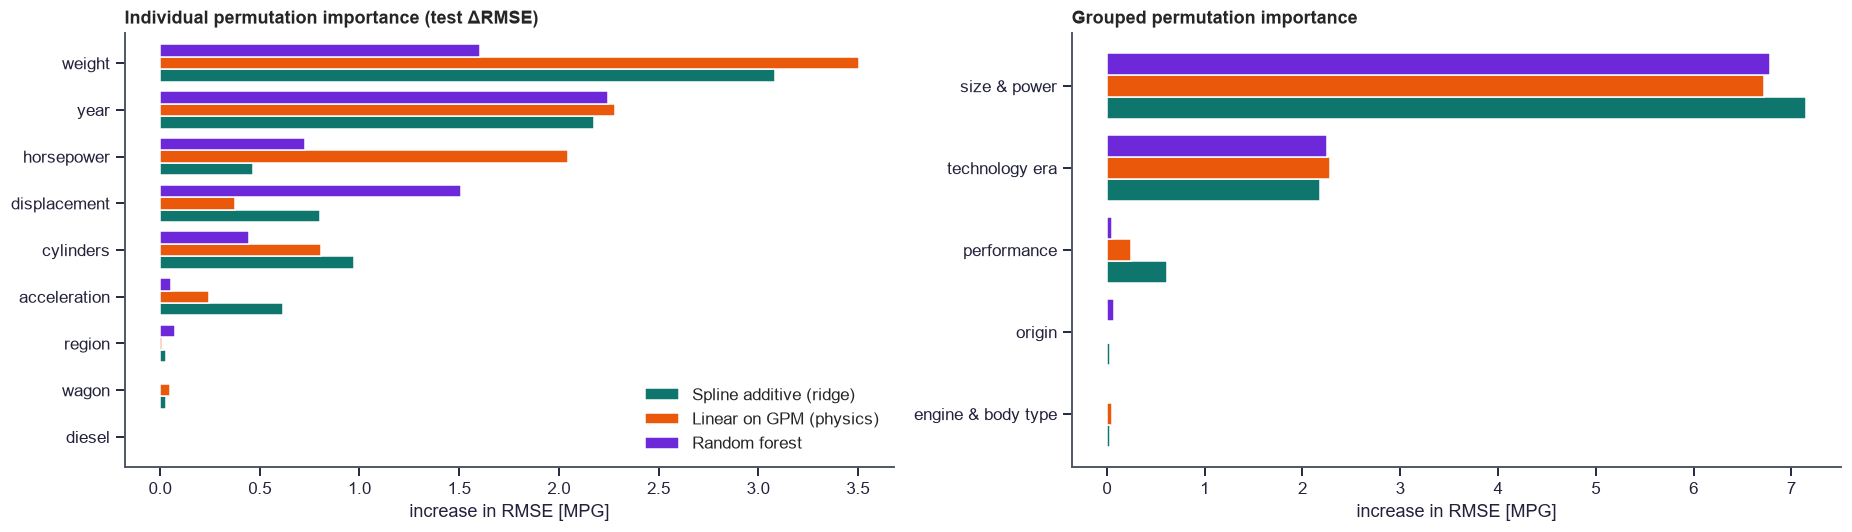

> **What we learn · domain.** For Spline additive (ridge), shuffling the size-and-power variables together raises RMSE by 7.15 MPG, while the four individual importances add up to only 5.33. The model year adds 2.18 MPG and origin only 0.03. Car size and era together carry most of the predictive information.

In [24]:
GROUPS = {"size & power": ["cylinders", "displacement", "horsepower", "weight"], "technology era": ["year"],
          "performance": ["acceleration"], "origin": ["region"], "engine & body type": ["diesel", "wagon"]}


def perm_importance(model, X, y, cols, repeats=30):
    r = np.random.default_rng(SEED)
    base = rmse(y, model.predict(X))
    out = []
    for _ in range(repeats):
        Xp = X.copy()
        idx = r.permutation(len(X))
        Xp[cols] = X[cols].to_numpy()[idx]
        out.append(rmse(y, model.predict(Xp)) - base)
    return np.mean(out), np.std(out)


interp_models = list(dict.fromkeys([CHAMPION, "OLS_GPM", "RF"]))
single = {MODEL_NAMES[k]: {c: perm_importance(tuned[k], X_test, y_test, [c])[0] for c in RAW_INPUTS} for k in interp_models}
grouped = {MODEL_NAMES[k]: {g: perm_importance(tuned[k], X_test, y_test, cols)[0] for g, cols in GROUPS.items()} for k in interp_models}
single, grouped = pd.DataFrame(single), pd.DataFrame(grouped)

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
single.loc[single.mean(axis=1).sort_values().index].plot(kind="barh", ax=axes[0], width=0.8)
axes[0].set(title="Individual permutation importance (test ΔRMSE)", xlabel="increase in RMSE [MPG]")
grouped.loc[grouped.mean(axis=1).sort_values().index].plot(kind="barh", ax=axes[1], width=0.8, legend=False)
axes[1].set(title="Grouped permutation importance", xlabel="increase in RMSE [MPG]")
fig.tight_layout()
savefig(fig, "9_1_importance")
plt.show()

c = MODEL_NAMES[CHAMPION]
size_sum = single.loc[GROUPS["size & power"], c].sum()
learn("domain", f"For {c}, shuffling the size-and-power variables together raises RMSE by {grouped.loc['size & power', c]:.2f} MPG, "
      f"while the four individual importances add up to only {size_sum:.2f}. The model year adds {grouped.loc['technology era', c]:.2f} MPG "
      f"and origin only {grouped.loc['origin', c]:.2f}. "
      + ("Car size and era together carry most of the predictive information."
         if grouped.loc[["size & power", "technology era"], c].sum() > 0.7 * grouped[c].clip(lower=0).sum()
         else "Predictive information is spread over several groups."))

### 9.2 Stability of coefficients
The original analysis found Lasso coefficients unstable across CV folds. Here the linear models are refitted on 300 bootstrap resamples of the training data. The spread of their standardised coefficients shows which effects the data pins down and which it cannot separate.

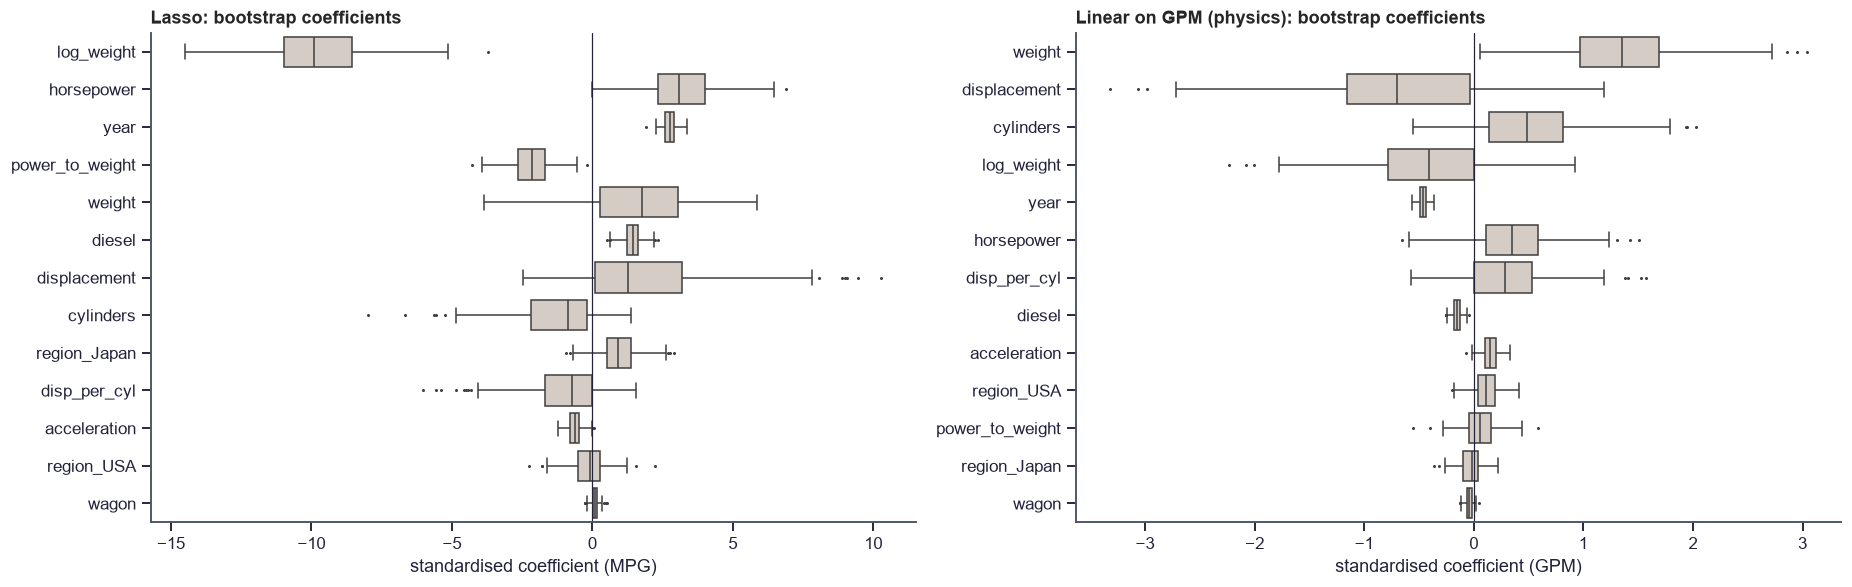

,coefficients changing sign in >10% of resamples
model,
Lasso,"wagon, disp_per_cyl, region_USA"
Linear on GPM (physics),"cylinders, displacement, horsepower, log_weigh..."


> **What we learn · modelling.** Coefficients whose sign changes in more than 10% of bootstrap resamples: Lasso: wagon, disp_per_cyl, region_USA. Linear on GPM (physics): cylinders, displacement, horsepower, log_weight, power_to_weight, disp_per_cyl, region_Japan, region_USA. These coefficients cannot be interpreted individually. Predictions and grouped effects do not depend on how the model splits the effect among correlated inputs.

In [25]:
def boot_coefs(key, n=300):
    r = np.random.default_rng(SEED)
    rows = []
    for _ in range(n):
        idx = r.integers(0, len(X_train), len(X_train))
        m = clone(tuned[key]).fit(X_train.iloc[idx], y_train.iloc[idx])
        est = m.named_steps["model"]
        est = getattr(est, "regressor_", est)
        rows.append(pd.Series(est.coef_, index=m.named_steps["prep"].get_feature_names_out()))
    return pd.DataFrame(rows)


coef_boot = {k: boot_coefs(k) for k in ["LASSO", "OLS_GPM"]}
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
stab_rows = []
for ax, (k, cb) in zip(axes, coef_boot.items()):
    cb.columns = [c.replace("num__", "").replace("region__", "") for c in cb.columns]
    order_c = cb.abs().median().sort_values(ascending=False).index
    sns.boxplot(data=cb[order_c], orient="h", ax=ax, color=SAND, fliersize=1)
    ax.axvline(0, c=INK, lw=0.8)
    ax.set(title=f"{MODEL_NAMES[k]}: bootstrap coefficients", xlabel="standardised coefficient" + (" (GPM)" if k == "OLS_GPM" else " (MPG)"))
    sign_flip = np.minimum((cb > 0).mean(), (cb < 0).mean()) > 0.1
    stab_rows.append({"model": MODEL_NAMES[k], "coefficients changing sign in >10% of resamples": ", ".join(cb.columns[sign_flip]) or "none"})
fig.tight_layout()
savefig(fig, "9_2_coef_stability")
plt.show()
display(pd.DataFrame(stab_rows).set_index("model"))
learn("modelling", "Coefficients whose sign changes in more than 10% of bootstrap resamples: "
      + " ".join(f"{r['model']}: {r['coefficients changing sign in >10% of resamples']}." for r in stab_rows)
      + " These coefficients cannot be interpreted individually. Predictions and grouped effects do not depend on how the model splits the effect among correlated inputs.")

### 9.3 Effect sizes in engineering units
The partial dependence of predicted MPG on weight, horsepower and model year is shown for the champion and for the physics model. Thin lines are ICE curves for individual test cars; the thick line is their average. The average marginal effects are then expressed per 100 kg of weight, per 10 hp and per model year, a form that can be compared directly with engineering intuition.

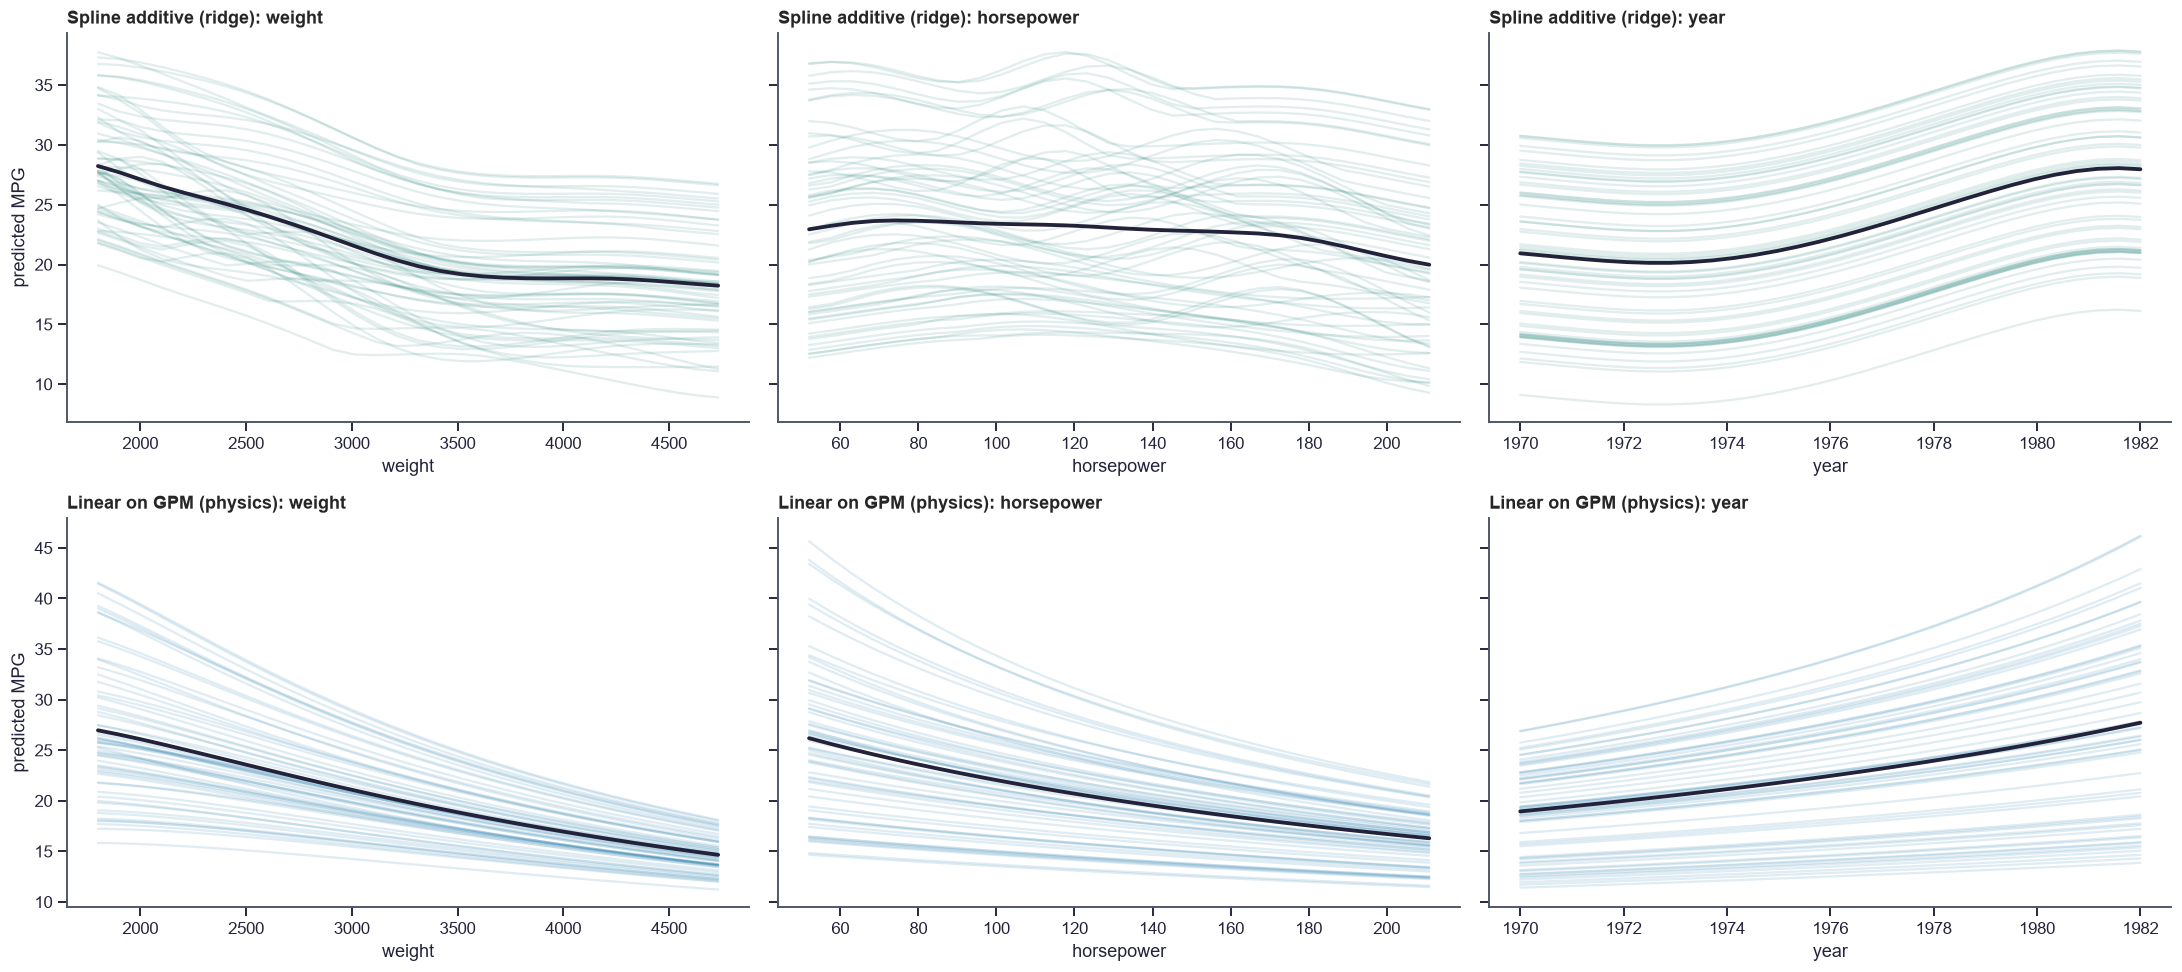

model,Linear on GPM (physics),Spline additive (ridge)
change,,
horsepower per +10 hp,-0.77,-0.53
weight per +100 kg,-1.10,-0.62
year per model year,+0.77,+0.40


> **What we learn · domain.** Average marginal effects from the champion model: horsepower per +10 hp: -0.53 MPG; weight per +100 kg: -0.62 MPG; year per model year: +0.40 MPG.

In [26]:
def ice(model, X, col, grid):
    return np.column_stack([model.predict(X.assign(**{col: v})) for v in grid])


fig, axes = plt.subplots(2, 3, figsize=(20, 9), sharey="row")
effects = []
for i, k in enumerate(list(dict.fromkeys([CHAMPION, "OLS_GPM"]))):
    for j, (col, step, unit) in enumerate([("weight", 100 / 0.45359, "per +100 kg"), ("horsepower", 10, "per +10 hp"), ("year", 1, "per model year")]):
        grid = np.linspace(*cars[col].quantile([0.02, 0.98]), 30)
        curves = ice(tuned[k], X_test.sample(min(60, len(X_test)), random_state=SEED), col, grid)
        ax = axes[i, j]
        ax.plot(grid, curves.T, color=FAMILY_COLORS[FAMILY[k]], alpha=0.12)
        ax.plot(grid, curves.mean(axis=0), color=INK, lw=2.5)
        ax.set(title=f"{MODEL_NAMES[k]}: {col}", xlabel=col, ylabel="predicted MPG" if j == 0 else "")
        base = tuned[k].predict(X_test)
        shifted = tuned[k].predict(X_test.assign(**{col: X_test[col] + step}))
        effects.append({"model": MODEL_NAMES[k], "change": f"{col} {unit}", "mean Δ MPG": np.nanmean(shifted - base)})
fig.tight_layout()
savefig(fig, "9_3_effects")
plt.show()
effects = pd.DataFrame(effects).pivot(index="change", columns="model", values="mean Δ MPG")
display(effects.style.format("{:+.2f}"))
learn("domain", "Average marginal effects from the champion model: " + "; ".join(f"{idx}: {v:+.2f} MPG" for idx, v in effects[MODEL_NAMES[CHAMPION]].items()) + ".")

## 10 · Data Requirements
Learning curves for the champion, the physics model and the random forest. For each training-set size the models are refitted five times on random subsets and scored on the fixed test set. Flexible models usually need more data before they overtake a correctly specified simple model. Where the curves are still falling at the full training size, more data would help.

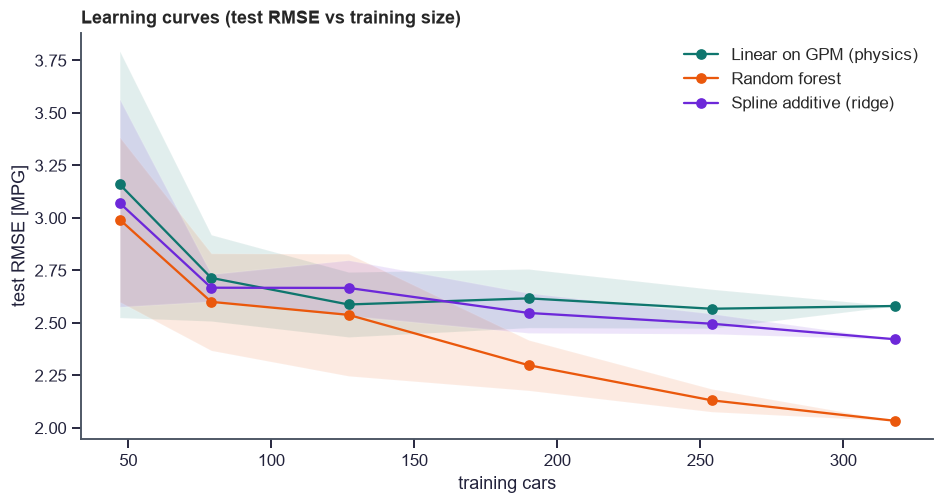

> **What we learn · modelling.** With only 47 training cars, the physics model reaches RMSE 3.16, against 2.99 for the random forest. At full size the figures are 2.58 and 2.03. Here the random forest is at least as data-efficient as the physics model.

In [27]:
fracs = [0.15, 0.25, 0.4, 0.6, 0.8, 1.0]
r = np.random.default_rng(SEED)
lc_rows = []
for k in list(dict.fromkeys([CHAMPION, "OLS_GPM", "RF"])):
    for f in fracs:
        for rep in range(1 if f == 1.0 else 5):
            idx = r.choice(len(X_train), int(f * len(X_train)), replace=False)
            m = clone(tuned[k]).fit(X_train.iloc[idx], y_train.iloc[idx])
            lc_rows.append({"model": MODEL_NAMES[k], "n": len(idx), "test RMSE": rmse(y_test, m.predict(X_test))})
lc = pd.DataFrame(lc_rows)
fig, ax = plt.subplots(figsize=(10, 4.8))
for mname, g in lc.groupby("model"):
    s = g.groupby("n")["test RMSE"].agg(["mean", "std"]).fillna(0)
    ax.plot(s.index, s["mean"], "o-", label=mname)
    ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], alpha=0.12)
ax.set(title="Learning curves (test RMSE vs training size)", xlabel="training cars", ylabel="test RMSE [MPG]")
ax.legend()
savefig(fig, "10_learning_curves")
plt.show()
small = lc[lc["n"] == lc["n"].min()].groupby("model")["test RMSE"].mean()
full = lc[lc["n"] == lc["n"].max()].groupby("model")["test RMSE"].mean()
learn("modelling", f"With only {lc['n'].min()} training cars, the physics model reaches RMSE {small[MODEL_NAMES['OLS_GPM']]:.2f}, "
      f"against {small[MODEL_NAMES['RF']]:.2f} for the random forest. At full size the figures are {full[MODEL_NAMES['OLS_GPM']]:.2f} and "
      f"{full[MODEL_NAMES['RF']]:.2f}. "
      + ("The model that encodes the physical structure is the more data-efficient one."
         if small[MODEL_NAMES['OLS_GPM']] < small[MODEL_NAMES['RF']] else
         "Here the random forest is at least as data-efficient as the physics model."))

## 11 · Prediction Tool and Export
`predict_mpg()` accepts a car specification and returns predicted MPG, the equivalent L/100 km, and a 90 % split-conformal prediction interval. The interval half-width is taken from the champion's out-of-fold residuals on the training set.

In [28]:
alpha = CONFIG["conformal_alpha"]
oof = cross_val_predict(clone(tuned[CHAMPION]), X_train, y_train, cv=KFold(5, shuffle=True, random_state=SEED), n_jobs=-1)
scores_abs = np.sort(np.abs(y_train - oof))
q_half = float(scores_abs[min(len(scores_abs) - 1, int(np.ceil((len(scores_abs) + 1) * (1 - alpha))) - 1)])
coverage = np.mean(np.abs(y_test - pred_test[CHAMPION]) <= q_half)


def predict_mpg(spec, model=None):
    model = model or tuned[CHAMPION]
    frame = pd.DataFrame([{**{"diesel": 0, "wagon": 0}, **spec}])[RAW_INPUTS]
    mpg = float(model.predict(frame)[0])
    return {"mpg": round(mpg, 1), "l_per_100km": round(235.215 / mpg, 1),
            f"{1 - alpha:.0%} interval (mpg)": (round(mpg - q_half, 1), round(mpg + q_half, 1))}


examples = {
    "1971 US V8 sedan": {"cylinders": 8, "displacement": 350, "horsepower": 165, "weight": 3700, "acceleration": 11.5, "year": 1971, "region": "USA"},
    "1976 Japanese compact": {"cylinders": 4, "displacement": 97, "horsepower": 75, "weight": 2200, "acceleration": 16.0, "year": 1976, "region": "Japan"},
    "1981 European diesel": {"cylinders": 4, "displacement": 141, "horsepower": 71, "weight": 3190, "acceleration": 24.8, "year": 1981, "region": "Europe", "diesel": 1},
}
display(pd.DataFrame({k: predict_mpg(v) for k, v in examples.items()}).T)
print(f"Conformal half-width ±{q_half:.2f} MPG; empirical test coverage {coverage:.1%} (nominal {1 - alpha:.0%})")

joblib.dump({"model": tuned[CHAMPION], "physics_model": tuned["OLS_GPM"], "inputs": RAW_INPUTS, "interval_halfwidth": q_half,
             "alpha": alpha}, DIRS["model"] / "mpg_model.joblib")
card = {"created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"), "champion": MODEL_NAMES[CHAMPION],
        "cv_rmse": float(tuning.loc[MODEL_NAMES[CHAMPION], "tuned CV RMSE"]), "test_rmse": float(champ_row["RMSE"]),
        "interval_halfwidth": q_half, "test_coverage": float(coverage), "versions": VERSIONS}
(DIRS["model"] / "model_card.json").write_text(json.dumps(card, indent=2, default=str))
test_df.assign(predicted_mpg=pred_test[CHAMPION]).to_csv(DIRS["tables"] / "test_predictions.csv", index=False)

,mpg,l_per_100km,90% interval (mpg)
1971 US V8 sedan,13.4,17.6,"(9.1, 17.6)"
1976 Japanese compact,29.6,8.0,"(25.3, 33.8)"
1981 European diesel,34.3,6.9,"(30.1, 38.6)"


Conformal half-width ±4.23 MPG; empirical test coverage 92.5% (nominal 90%)


---
## 12 · Key Learnings

### 12.1 Findings from this run
All "What we learn" boxes from the notebook, grouped by theme.

In [29]:
TITLES = {"domain": "What the data says about cars", "data": "What we learn about the data itself",
          "modelling": "What we learn about modelling", "process": "What we learn about the analysis process"}
for cat in ["domain", "data", "modelling", "process"]:
    if LEARNINGS.get(cat):
        display(Markdown(f"#### {TITLES[cat]}\n" + "\n".join(f"{i}. {t}" for i, t in enumerate(LEARNINGS[cat], 1))))

#### What the data says about cars
1. Fuel consumption (GPM) depends on weight much more linearly than MPG does: a straight line explains R² = 0.784 of GPM variation, against 0.692 for MPG. The curved relationship noted in the original EDA is mostly a consequence of measuring efficiency as distance per gallon rather than fuel per distance.
2. Holding weight constant, fuel consumption fell by about 3.2% per model year. A 10% heavier car uses about 9.1% more fuel (elasticity 0.91). Between 1970 and 1982, lighter cars account for 44% of the fall in average fuel consumption and technology at equal weight for 56%.
3. Raw MPG advantage over US cars: Europe +39% raw vs +5% at equal weight, power and year, Japan +52% raw vs +4% at equal weight, power and year. Most of the apparent regional advantage comes from car size, a classic case of confounding.
4. Diesel cars use about 19% less fuel than petrol cars of the same weight, power and year. The numeric inputs cannot express this, so the diesel flag taken from the names adds new information.
5. For Spline additive (ridge), shuffling the size-and-power variables together raises RMSE by 7.15 MPG, while the four individual importances add up to only 5.33. The model year adds 2.18 MPG and origin only 0.03. Car size and era together carry most of the predictive information.
6. Average marginal effects from the champion model: horsepower per +10 hp: -0.53 MPG; weight per +100 kg: -0.62 MPG; year per model year: +0.40 MPG.

#### What we learn about the data itself
1. The dataset has 398 cars and 6 missing horsepower values. 305 distinct names appear, so some car models are recorded more than once. The names reveal 9 diesel cars and 29 station wagons, information that no numeric column contains.
2. 3 of the 6 numeric inputs have VIF > 10 (displacement 20, weight 11, cylinders 11). These variables share most of their information, so any single coefficient or importance score for one of them should not be read as that variable's separate effect.

#### What we learn about modelling
1. The best cross-validated model is Spline additive (ridge) (RMSE 2.61 MPG). 9 models are statistically indistinguishable from it (corrected p > 0.05): Spline additive (ridge), XGBoost, Gaussian process, Gradient boosting, Linear on log MPG, MLP, SVR (RBF), LightGBM, Random forest. No simpler model comes within one standard error, so the one-standard-error rule keeps it.
2. The engineered features (diesel, wagon, log weight, ratios) lower CV RMSE for 15 of 15 models, by 0.21 MPG at the median and by up to 0.62 MPG (Ridge). The physics-motivated linear model on GPM reaches 3.02 MPG, compared with 2.85 for the same model on MPG, so the target transformation does not help the linear model here.
3. Tuning improved CV RMSE by 0.039 MPG at the median, and by at most 0.15 MPG (Elastic Net), compared with a median gain of 0.209 MPG from the engineered features. On this dataset, better features matter more than hyperparameter search. The champion after tuning is Spline additive (ridge).
4. On the hold-out set, Spline additive (ridge) reaches RMSE 2.42 MPG (95% CI 1.95–2.85), against 7.35 for the mean baseline. The width of that interval shows that 80 test cars cannot separate models whose errors differ by a few tenths of an MPG.
5. The correlation between error size and predicted value is 0.05 on the MPG scale and 0.56 on the GPM scale. The pattern remains on the GPM scale, so the model is less accurate for some cars for reasons other than the measurement scale.
6. Coefficients whose sign changes in more than 10% of bootstrap resamples: Lasso: wagon, disp_per_cyl, region_USA. Linear on GPM (physics): cylinders, displacement, horsepower, log_weight, power_to_weight, disp_per_cyl, region_Japan, region_USA. These coefficients cannot be interpreted individually. Predictions and grouped effects do not depend on how the model splits the effect among correlated inputs.
7. With only 47 training cars, the physics model reaches RMSE 3.16, against 2.99 for the random forest. At full size the figures are 2.58 and 2.03. Here the random forest is at least as data-efficient as the physics model.

#### What we learn about the analysis process
1. Across 30 random splits, the random forest's test RMSE ranged from 1.91 to 3.61 MPG using the same method throughout. That spread of 1.69 MPG is the uncertainty attached to any single-split number such as 2.27. The most frequent winner was Spline additive (ridge) (67% of splits).
2. Keeping every car name wholly in either training or validation changes CV RMSE by between -0.04 and -0.00 MPG. Repeated car models make random-split scores essentially unaffected for this dataset.

### 12.2 Methodological lessons from revisiting the original project
These lessons are general and do not depend on this run's numbers.

1. **Choose the target's scale on physical grounds.** Fuel use per distance is roughly proportional to mass. Modelling GPM instead of MPG can turn a curved relationship into a nearly straight one, letting a simple linear model compete with ensembles, and can explain the "less accurate for high-MPG cars" pattern. §3.1, §5.3 and §7.2 test how far this holds for this data.
2. **Look for information in the text columns.** The original pipeline dropped the car names. Those names are the only source of the diesel and wagon flags, which §3.5 and §5.3 show to carry information that the numeric columns lack.
3. **Treat a single test score as a sample, not a fact.** With 80 test cars, the split alone changes the RMSE noticeably (§8.1 measures by how much). Repeated CV, bootstrap intervals and corrected significance tests are needed before one model can be called better than another.
4. **Prefer the simplest model within noise.** When several models are statistically tied, the one-standard-error rule favours the simpler and more interpretable one. This replaces reading a regularisation depth off a learning-curve plot by eye.
5. **Use the test set once, and validate everything else by cross-validation.** Here, tuning, model choice and the interval calibration all use training data only.
6. **Interpret correlated inputs as groups.** Impurity importances and single coefficients spread the effect of car size across four correlated variables. Grouped permutation importance and bootstrap coefficient spreads show what is actually identifiable.
7. **Separate composition from genuine effects.** Raw regional differences partly reflect car size. Only a model that adjusts for size and year shows the part that relates to engineering (§3.4).
8. **Keep every preprocessing step inside the pipeline.** Imputation, scaling, encoding and feature construction are refitted in each fold, so no information from validation or test cars reaches training.

### 12.3 Limits of the data
- **Period and market.** The data cover cars sold in the USA between 1970 and 1982. The effects found here, such as the size of the yearly technology gain, describe that period and should not be applied to modern vehicles.
- **Missing drivers of fuel use.** Aerodynamics, transmission type, gearing, tyres and the test driving cycle are not recorded. They account for much of the error the models cannot remove.
- **Sample size.** With 398 cars, several of which are the same model in different years, the precision of every estimate is limited. Rare configurations, such as 3- and 5-cylinder engines and diesels, are represented by only a handful of cars.
- **Measurement.** MPG values come from test cycles of their time and are rounded, which adds noise that no model can remove.

In [30]:
archive = shutil.make_archive(str(HOME), "zip", HOME)
print(f"Results archive: {archive} ({Path(archive).stat().st_size / 1e6:.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(archive)

Results archive: C:\Users\Ekta Jain\Downloads\nb_run\repos\auto-mpg-fuel-economy\notebooks\auto_mpg_study.zip (3.5 MB)


---
**References.** Quinlan, R. (1993). *Combining instance-based and model-based learning.* ICML — origin of the Auto MPG data (UCI Machine Learning Repository) · Nadeau & Bengio (2003), *Inference for the generalization error* · Hastie, Tibshirani & Friedman (2009), *The Elements of Statistical Learning* (one-standard-error rule) · Strobl et al. (2007), *Bias in random forest variable importance measures* · Vovk, Gammerman & Shafer (2005), *Algorithmic Learning in a Random World*.